# ERCOT 2025 Electricity Demand Forecasting

## 1. Problem Definition  
**Objective:** Predict all 24 hourly ERCOT system electricity load (MW) of the following day using historical load and calendar information.

**Prediction target:** ERCOT system load (MW) for each predicted hour

**Forecast horizon:** 24 hours ahead (day-ahead hourly profile)

**Problem type:** Supervised regression

## 2. Data Loading & Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.options.display.max_columns = None
pd.set_option('display.expand_frame_repr', False) #prevent pandas from breaking columns onto new lines when displaying df
pd.set_option('display.width', 1000) #set wide width to display all columns in df

filename = '../Data/Native_Load_2025.xlsx'

df = pd.read_excel(filename)
print("Dataset dimensions:", df.shape)
df.head(5)

Dataset dimensions: (8760, 10)


,Hour Ending,COAST,EAST,FWEST,NORTH,NCENT,SOUTH,SCENT,WEST,ERCOT
0,01/01/2025 01:00,10538.553193,1545.465863,7090.619810,1388.565588,11964.866264,3012.769998,6447.297871,1235.721317,43223.859905
1,01/01/2025 02:00,10477.912860,1553.994477,7040.460607,1390.392647,12064.919506,2962.803597,6382.650858,1249.397659,43122.532212
2,01/01/2025 03:00,10363.015361,1534.575620,7028.741719,1390.634577,12040.262276,2981.433181,6320.119991,1259.729121,42918.511847
3,01/01/2025 04:00,10259.984795,1548.084385,6992.734978,1402.423965,12055.424000,2970.761172,6277.132219,1274.238069,42780.783583
4,01/01/2025 05:00,10332.692971,1585.772017,7026.066195,1425.900669,12307.605237,2975.631819,6298.522746,1301.043053,43253.234707


In [2]:
print("Hour Ending data type:", df['Hour Ending'].dtype)

Hour Ending data type: str


### Data Inspection Comment: 
The data contains 10 columns, with the first column being the timestamp (date & time) and the last column being the total ERCOT demand. Columns 2-9 represent different weather zones within ERCOT. The data has a total of 8760 rows, which corresponds to the number of hours in a non-leap year (365 days * 24 hours). The DataType for the Hour Ending Column was also confirmed to be string, this will need to be changed to allow for easier processing.

## 3. Data Preprocessing & Validation

### 3.1 Prepare Timestamps

In [3]:
contains_24 = df["Hour Ending"].str.contains("24:00") #Identify midnight-ending observations
print("Number of observations containing 24:00:", contains_24.sum())

dst_time = df[df["Hour Ending"].str.contains("DST")] #Inspect DST labels
dst_time

Number of observations containing 24:00: 365


,Hour Ending,COAST,EAST,FWEST,NORTH,NCENT,SOUTH,SCENT,WEST,ERCOT
7321,11/02/2025 02:00 DST,10157.466148,1257.118263,7314.137127,1065.831053,9595.716227,3287.662656,5869.605272,1122.569795,39670.106541


Comment: 365 observations use 24:00 as previously noted in the analysis, which represents the midnight time at the end of that reporting day. DST also introduces days with 23 or 25 hourly observations instead of 24 hours. These will need to be addressed accordingly before the ML pipeline is created.

### 3.2 Create the Reporting Date Feature

In [4]:
date_strings = df["Hour Ending"].str.split(' ').str[0] #Extract the date portion from Hour Ending column

datetime_dates = pd.to_datetime(date_strings, format='%m/%d/%Y') #Convert into pandas datetime type

df['ReportingDate'] = datetime_dates #Store it in a new DataFrame column

print(df[['Hour Ending', 'ReportingDate']].head(24)) #Verify result

         Hour Ending ReportingDate
0   01/01/2025 01:00    2025-01-01
1   01/01/2025 02:00    2025-01-01
2   01/01/2025 03:00    2025-01-01
3   01/01/2025 04:00    2025-01-01
4   01/01/2025 05:00    2025-01-01
5   01/01/2025 06:00    2025-01-01
6   01/01/2025 07:00    2025-01-01
7   01/01/2025 08:00    2025-01-01
8   01/01/2025 09:00    2025-01-01
9   01/01/2025 10:00    2025-01-01
10  01/01/2025 11:00    2025-01-01
11  01/01/2025 12:00    2025-01-01
12  01/01/2025 13:00    2025-01-01
13  01/01/2025 14:00    2025-01-01
14  01/01/2025 15:00    2025-01-01
15  01/01/2025 16:00    2025-01-01
16  01/01/2025 17:00    2025-01-01
17  01/01/2025 18:00    2025-01-01
18  01/01/2025 19:00    2025-01-01
19  01/01/2025 20:00    2025-01-01
20  01/01/2025 21:00    2025-01-01
21  01/01/2025 22:00    2025-01-01
22  01/01/2025 23:00    2025-01-01
23  01/01/2025 24:00    2025-01-01


In [5]:
display(df.loc[contains_24, ['Hour Ending', 'ReportingDate']].head()) #Verify reporting dates for midnight-ending observations

,Hour Ending,ReportingDate
23,01/01/2025 24:00,2025-01-01
47,01/02/2025 24:00,2025-01-02
71,01/03/2025 24:00,2025-01-03
95,01/04/2025 24:00,2025-01-04
119,01/05/2025 24:00,2025-01-05


Comment: The reporting date was extracted from the original Hour Ending column to preserve the correct day assignment for the midnight-ending observations.

### 3.3 Check Daily Observation Counts & DST Validation

In [6]:
daily_counts = df.groupby('ReportingDate').size() #count observations for each reporting date
print("Frequency of daily observation counts:")
print(daily_counts.value_counts())

anomalous_dates = daily_counts[daily_counts != 24] #count dates that do not have exactly 24 observations

print("\nDates that do not contain exactly 24 observations:")
print(anomalous_dates)

Frequency of daily observation counts:
24    363
23      1
25      1
Name: count, dtype: int64

Dates that do not contain exactly 24 observations:
ReportingDate
2025-03-09    23
2025-11-02    25
dtype: int64


Comment: Only 363 days have the full 24 hour count. Due to Daylight Saving Time (DST), November 2 had 25 hour count due to additional hour gained and March 9 had 23 hour count due to the time lost.

###  3.4 DST Handling & Final Data Validation

In [7]:
valid_dates = daily_counts[daily_counts == 24].index #select reporting dates with exactly 24 observations

forecast_df = df[df['ReportingDate'].isin(valid_dates)].copy() #filter the original DataFrame to only include valid dates rows

print("Reporting dates retained:", forecast_df['ReportingDate'].nunique())
print("Hourly observations retained:", forecast_df.shape[0])
print("Observations excluded from the forecast dataset:", df.shape[0] - forecast_df.shape[0])
print("Observations in original dataset:", df.shape[0])

Reporting dates retained: 363
Hourly observations retained: 8712
Observations excluded from the forecast dataset: 48
Observations in original dataset: 8760


### Data Preprocessing Decision Comment: 
The original dataset contains 365 reporting dates, including two DST transition dates with 23 and 25 hourly observations, respectively. For the initial forecasting experiment, I retained only dates containing exactly 24 hourly observations in a dataframe called forecast_df. This reduced the target dataset to 363 reporting dates (8,712 observations). This decision ensures that each forecast target represents a complete, fixed-length 24-hour daily profile. The original dataset is preserved separately so historical observations from DST transition dates can still be considered when constructing lag features.

## 4. Feature Engineering & Target Construction

### 4.1 Define the Forecasting Setup

The following setup will be used for the intial experiment:  

- **Forecast issuance:**    Immediately after the previous reporting day's final hourly load becomes available
- **Prediction:**   All 24 hourly load observations for the next reporting day
- **Target (y):**   Actual ERCOT system load (MW) for each predicted hour
- **Historical inputs:**    Load observations available by the forecast issuance cutoff
- **Calendar inputs:**  Target hour, day of week, month, etc.
- **Initial scope:**    Ordinary 24-observation target days  

The model predicts ERCOT system load for each hour of the following reporting day. Forecasts are issued after the previous reporting day's final hourly observation is available. 

### 4.2 Feature Selection

The following are a list of selected features and why they were selected:  

- **Hour:** Electicity demand changes throughout the day
- **DayOfWeek:**    Weekdays and weekends have different demand patterns
- **Month:**    Captures seasonal changes
- **Historical load:**  Provides information about recent electricity demand  

Only historical load available at issuance and known calendar information are used as features.

### 4.3 Calendar Feature Engineering

In [8]:
#Extract day of the week from ReportingDate column
forecast_df['DayOfWeek'] = forecast_df['ReportingDate'].dt.dayofweek 
print("Extracted Day of the Week:")
print(forecast_df[['ReportingDate', 'DayOfWeek']].head())

#Extract month from ReportingDate column
forecast_df['Month'] = forecast_df['ReportingDate'].dt.month 
print("\nExtracted Month:")
print(forecast_df[['ReportingDate', 'Month']].head())

#Extract the hour from Hour Ending column
forecast_df['Hour'] = (
    forecast_df['Hour Ending']
    .str.split(' ').str[1]
    .str.split(':').str[0]
    .astype(int)
)
print("\nExtracted Hour:")
print(forecast_df[['Hour Ending', 'Hour']].head())

print(f"\nMinimum Hour: {forecast_df['Hour'].min()}")
print(f"Maximum Hour: {forecast_df['Hour'].max()}")

Extracted Day of the Week:
  ReportingDate  DayOfWeek
0    2025-01-01          2
1    2025-01-01          2
2    2025-01-01          2
3    2025-01-01          2
4    2025-01-01          2

Extracted Month:
  ReportingDate  Month
0    2025-01-01      1
1    2025-01-01      1
2    2025-01-01      1
3    2025-01-01      1
4    2025-01-01      1

Extracted Hour:
        Hour Ending  Hour
0  01/01/2025 01:00     1
1  01/01/2025 02:00     2
2  01/01/2025 03:00     3
3  01/01/2025 04:00     4
4  01/01/2025 05:00     5

Minimum Hour: 1
Maximum Hour: 24


#### Calendar Feature Engineering Comment: 
Calendar features were represented numerically: day of week (Monday = 0 through Sunday = 6), month (1–12), and hour ending (1–24). These integer representations are convenient for modeling, although they do not explicitly capture cyclical relationships. Alternative encodings could be investigated in future work.

### 4.4 Historical Load Feature Engineering

#### 4.4.1 Historical Data Preparation

In [9]:
#1. Identify Duplicate Date-Hour Rows based on ReportingDate and Hour columns
duplicate_rows = forecast_df[ 
    forecast_df.duplicated(
        subset=['ReportingDate', 'Hour'], 
        keep=False)]
 
duplicated_rows_count = duplicate_rows.shape[0] #Count the number of duplicate rows
print(f"\nNumber of duplicate rows based on ReportingDate and Hour: {duplicated_rows_count}")


Number of duplicate rows based on ReportingDate and Hour: 0


In [10]:
#2. Create PreviousDate column in forecast_df
forecast_df['PreviousDate'] = forecast_df['ReportingDate'] - pd.Timedelta(days=1) #Create PreviousDate column in forecast_df
print("\nPreviousDate column added:")
print(forecast_df[['ReportingDate', 'Hour', 'PreviousDate']].head())


PreviousDate column added:
  ReportingDate  Hour PreviousDate
0    2025-01-01     1   2024-12-31
1    2025-01-01     2   2024-12-31
2    2025-01-01     3   2024-12-31
3    2025-01-01     4   2024-12-31
4    2025-01-01     5   2024-12-31


In [11]:
#3. Create historical_df DataFrame containing ReportingDate, Hour, and ERCOT columns
df['Hour'] = (      
    df['Hour Ending']
    .str.split(' ').str[1]
    .str.split(':').str[0]
    .astype(int)
)

historical_df = df[['ReportingDate', 'Hour', 'ERCOT']].copy()
print("\nERCOT demand column added to historical_df:")     
print(historical_df.head())

historical_df.shape


ERCOT demand column added to historical_df:
  ReportingDate  Hour         ERCOT
0    2025-01-01     1  43223.859905
1    2025-01-01     2  43122.532212
2    2025-01-01     3  42918.511847
3    2025-01-01     4  42780.783583
4    2025-01-01     5  43253.234707


(8760, 3)

In [12]:
#4. Identify DST duplicate rows in historical_df based on ReportingDate and Hour columns
duplicate_rows_historical = historical_df[
    historical_df.duplicated(
        subset=['ReportingDate', 'Hour'], 
        keep=False
    )
]

duplicated_rows_historical_count = duplicate_rows_historical.shape[0]
print(f"\nNumber of duplicate rows in historical_df: {duplicated_rows_historical_count}")
display(duplicate_rows_historical)


Number of duplicate rows in historical_df: 2


,ReportingDate,Hour,ERCOT
7320,2025-11-02,2,40309.206275
7321,2025-11-02,2,39670.106541


In [13]:
#5. Create a new DataFrame, historical_unique, by dropping duplicate rows based on ReportingDate and Hour columns
historical_unique = historical_df.drop_duplicates(
    subset=['ReportingDate', 'Hour'], 
    keep=False
    )
print(f"\nUnique rows in historical_unique: {historical_unique.duplicated(
    subset=['ReportingDate', 'Hour']).sum()}") #Verify that there are no duplicate rows in historical_unique
print(f'Number of unique rows in historical_unique: {historical_unique.shape[0]}')


Unique rows in historical_unique: 0
Number of unique rows in historical_unique: 8758


##### **Historical Data Preparation Comment:** 
I created a separate historical load dataset (historical_df) using reporting dates, hour-ending labels, and ERCOT system load. I identified two records with the same reporting date and hour during the November DST transition. Because these observations represent different periods, I created historical_unique DF which excluded both ambiguous date-hour records from the historical lookup (using keep=False) rather than arbitrarily selecting or averaging them. This ensures that each historical date-hour key corresponds to at most one load observation, preventing ambiguous matches and unintended row duplication during merging. 

#### 4.4.2 Lag Feature Construction

In [14]:
#1. Create ERCOT 1-Day Lag Features by merging historical load with forecast targets
merge_df = pd.merge(
    forecast_df,
    historical_unique[['ReportingDate', 'Hour', 'ERCOT']],
    left_on=['PreviousDate', 'Hour'],
    right_on=['ReportingDate', 'Hour'],
    how='left',     #use Left Join to match where PreviousDate in forecast_df corresponds to ReportingDate in historical_unique
    suffixes=('', '_Previous'),
    validate='m:1'
)

# Rename historical load column to ERCOT_Lag_1_Day
merge_df = merge_df.rename(columns={'ERCOT_Previous': 'ERCOT_Lag_1_Day'})

# Check ERCOT_Lag_1_Day values to confirm number of NaN values as 26
display(merge_df[['ReportingDate', 'Hour', 'ERCOT', 'ERCOT_Lag_1_Day']].head(26))

print("Missing lag values:", merge_df['ERCOT_Lag_1_Day'].isna().sum())

display(
    merge_df.loc[
        merge_df['ERCOT_Lag_1_Day'].isna(),
        ['ReportingDate', 'Hour', 'PreviousDate', 'ERCOT_Lag_1_Day']
    ]
)

,ReportingDate,Hour,ERCOT,ERCOT_Lag_1_Day
0,2025-01-01,1,43223.859905,NaN
1,2025-01-01,2,43122.532212,NaN
2,2025-01-01,3,42918.511847,NaN
3,2025-01-01,4,42780.783583,NaN
4,2025-01-01,5,43253.234707,NaN
5,2025-01-01,6,43984.988292,NaN
6,2025-01-01,7,45192.086546,NaN
7,2025-01-01,8,46051.468502,NaN
8,2025-01-01,9,46388.191183,NaN
9,2025-01-01,10,46310.569451,NaN


Missing lag values: 26


,ReportingDate,Hour,PreviousDate,ERCOT_Lag_1_Day
0,2025-01-01,1,2024-12-31,NaN
1,2025-01-01,2,2024-12-31,NaN
2,2025-01-01,3,2024-12-31,NaN
3,2025-01-01,4,2024-12-31,NaN
4,2025-01-01,5,2024-12-31,NaN
5,2025-01-01,6,2024-12-31,NaN
6,2025-01-01,7,2024-12-31,NaN
7,2025-01-01,8,2024-12-31,NaN
8,2025-01-01,9,2024-12-31,NaN
9,2025-01-01,10,2024-12-31,NaN


In [15]:
#2. Create 7-day lag features by merging historical load with forecast targets
merge_df["PreviousWeekDate"] = merge_df["ReportingDate"] - pd.to_timedelta(
    7, unit="D"
)

merge_df = pd.merge(
    merge_df,
    historical_unique[["ReportingDate", "Hour", "ERCOT"]],
    left_on=["PreviousWeekDate", "Hour"],
    right_on=["ReportingDate", "Hour"],
    how="left",
    suffixes=("", "_hist_7d"),
    validate='m:1'
)

merge_df = merge_df.rename(columns={"ERCOT_hist_7d": "ERCOT_Lag_7_Days"})

# If an extra 'ReportingDate_hist_7d' column was created during merge, drop it
if "ReportingDate_hist_7d" in merge_df.columns:
    merge_df = merge_df.drop(columns=["ReportingDate_hist_7d"])

# Display the two lag columns alongside ReportingDate, Hour, and ERCOT
display_cols = [
    "ReportingDate",
    "Hour",
    "ERCOT",
    "ERCOT_Lag_1_Day",
    "ERCOT_Lag_7_Days",
]
print("--- Sample DataFrame Output ---")
print(merge_df[display_cols].head())

# Print the number of missing values in the seven-day lag column
missing_7d = merge_df["ERCOT_Lag_7_Days"].isna().sum()
print(f"\nNumber of missing values in ERCOT_Lag_7_Days: {missing_7d}")

--- Sample DataFrame Output ---
  ReportingDate  Hour         ERCOT  ERCOT_Lag_1_Day  ERCOT_Lag_7_Days
0    2025-01-01     1  43223.859905              NaN               NaN
1    2025-01-01     2  43122.532212              NaN               NaN
2    2025-01-01     3  42918.511847              NaN               NaN
3    2025-01-01     4  42780.783583              NaN               NaN
4    2025-01-01     5  43253.234707              NaN               NaN

Number of missing values in ERCOT_Lag_7_Days: 170


##### Lag Feature Construction Comment:
I engineered two historical electricity-demand features:

- One-day lag: Actual ERCOT load from the same hour on the preceding reporting date.

- Seven-day lag: Actual ERCOT load from the same hour seven calendar days earlier.

I used date-hour joins rather than simply shifting rows because daylight saving time transitions cause some reporting days to contain 23 or 25 observations. A fixed row shift could therefore misalign the intended historical hour. The one-day lag contained 26 missing values: 24 from unavailable December 2024 history and two from DST-related hour mismatches. The seven-day lag contained 170 missing values: 168 from the first seven days of 2025 and two from DST-related hour mismatches. These features use historical observations rather than actual demand from the day being forecast.

#### 4.4.3 Feature Validation

In [16]:
# Check the number of observations after merging
print("Rows in forecast_df:", len(forecast_df))
print("Rows in merge_df:", len(merge_df))

# Check missing historical features
lag_columns = ["ERCOT_Lag_1_Day", "ERCOT_Lag_7_Days"]

print("\nMissing values in lag features:")
print(merge_df[lag_columns].isna().sum())

# Count rows with at least one missing lag feature
missing_rows = merge_df[lag_columns].isna().any(axis=1).sum()
print("\nRows with missing lag features:", missing_rows)

# Create clean modeling dataset
model_df = merge_df.dropna(subset=lag_columns).copy()

print("\nFinal modeling dataset dimensions:", model_df.shape)
print("Reporting dates retained:", model_df["ReportingDate"].nunique())

# Preview model-ready features
display(
    model_df[
        [
            "ReportingDate",
            "Hour",
            "DayOfWeek",
            "Month",
            "ERCOT_Lag_1_Day",
            "ERCOT_Lag_7_Days",
            "ERCOT"
        ]
    ].head()
)

Rows in forecast_df: 8712
Rows in merge_df: 8712

Missing values in lag features:
ERCOT_Lag_1_Day      26
ERCOT_Lag_7_Days    170
dtype: int64

Rows with missing lag features: 172

Final modeling dataset dimensions: (8540, 19)
Reporting dates retained: 356


,ReportingDate,Hour,DayOfWeek,Month,ERCOT_Lag_1_Day,ERCOT_Lag_7_Days,ERCOT
168,2025-01-08,1,2,1,59023.554750,43223.859905,57618.872945
169,2025-01-08,2,2,1,58320.903323,43122.532212,57291.027786
170,2025-01-08,3,2,1,58657.275583,42918.511847,57313.013686
171,2025-01-08,4,2,1,59329.409042,42780.783583,57884.611739
172,2025-01-08,5,2,1,60920.911584,43253.234707,59145.265049


### 4.5 Target Construction

In [17]:
#1. Identify reporting dates with all 24 hourly observations
complete_dates = model_df.groupby("ReportingDate").size()
complete_dates = complete_dates[complete_dates == 24].index

# Keep only complete reporting dates
model_df = model_df[
    model_df["ReportingDate"].isin(complete_dates)
].copy()

# Validate the final dataset
print("Final modeling observations:", len(model_df))
print("Complete reporting dates:", model_df["ReportingDate"].nunique())
print("Observations per day:", model_df.groupby("ReportingDate").size().unique())


Final modeling observations: 8448
Complete reporting dates: 352
Observations per day: [24]


In [18]:
#2. Define the features and target for modeling
X = model_df[["Hour", "DayOfWeek", "Month", "ERCOT_Lag_1_Day", "ERCOT_Lag_7_Days"]]
y = model_df["ERCOT"]

print("\nFeature columns:", X.shape)
print("Target column:", y.shape[0])
print("\nFeature columns preview:")
display(X.head())
print("\nTarget column preview:")
display(y.head())


Feature columns: (8448, 5)
Target column: 8448

Feature columns preview:


,Hour,DayOfWeek,Month,ERCOT_Lag_1_Day,ERCOT_Lag_7_Days
168,1,2,1,59023.554750,43223.859905
169,2,2,1,58320.903323,43122.532212
170,3,2,1,58657.275583,42918.511847
171,4,2,1,59329.409042,42780.783583
172,5,2,1,60920.911584,43253.234707



Target column preview:


168    57618.872945
169    57291.027786
170    57313.013686
171    57884.611739
172    59145.265049
Name: ERCOT, dtype: float64

### Feature Engineering & Target Construction Comment:
After merging the historical load features, I identified 172 observations missing at least one required lag value. Removing these observations left 8,540 hourly records. However, four reporting dates (March 10, March 16, November 3, and November 9) subsequently contained only 23 usable observations. Since the project aims to predict complete 24-hour daily load profiles, I excluded these incomplete dates.

The final modeling dataset contains 8,448 hourly observations across 352 complete reporting dates. I defined five input variables/predictors: hour, day of week, month, previous-day load, and previous-week load. The target variable is actual ERCOT system electricity demand, measured in MW. Each row represents one hourly target within a day-ahead forecasting profile.

## 5. Chronological Train/Validation/Test Split

### 5.1 Determine Chronological Split Boundaries

In [19]:
# Extract unique ReportingDate values and sort chronologically
unique_dates = np.sort(model_df['ReportingDate'].unique())
total_dates = len(unique_dates)     #Count total number of unique dates

# Calculate integer counts for partitions (70% Train, 15% Validation, 15% Test)
n_train = int(total_dates * 0.70)
n_val = int(total_dates * 0.15)
n_test = total_dates - n_train - n_val

# Identify the first date in each of the three partitions
first_train_date = unique_dates[0]
first_val_date = unique_dates[n_train]
first_test_date = unique_dates[n_train + n_val]

# Print total dates and partition sizes
print(f"Total unique dates: {total_dates}")
print(f"Train size: {n_train} dates (Starts: {first_train_date})")
print(f"Validation size: {n_val} dates (Starts: {first_val_date})")
print(f"Test size: {n_test} dates (Starts: {first_test_date})")

Total unique dates: 352
Train size: 246 dates (Starts: 2025-01-08T00:00:00.000000)
Validation size: 52 dates (Starts: 2025-09-14T00:00:00.000000)
Test size: 54 dates (Starts: 2025-11-07T00:00:00.000000)


### 5.2 Create Training, Validation, and Test Sets

In [20]:
# Divide unique_dates into three arrays using slicing
train_dates = unique_dates[:n_train]
val_dates = unique_dates[n_train : n_train + n_val]
test_dates = unique_dates[n_train + n_val :]

# Define features and target and create the six variables for training, validation, and testing
predictors = ["Hour", "DayOfWeek", "Month", "ERCOT_Lag_1_Day", "ERCOT_Lag_7_Days"]
target = "ERCOT"

X_train = model_df[model_df["ReportingDate"].isin(train_dates)][predictors]
y_train = model_df[model_df["ReportingDate"].isin(train_dates)][target]

X_val = model_df[model_df["ReportingDate"].isin(val_dates)][predictors]
y_val = model_df[model_df["ReportingDate"].isin(val_dates)][target]

X_test = model_df[model_df["ReportingDate"].isin(test_dates)][predictors]
y_test = model_df[model_df["ReportingDate"].isin(test_dates)][target]

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape[0]}")
print(f"X_val shape:   {X_val.shape}, y_val shape:   {y_val.shape[0]}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape[0]}")

X_train shape: (5904, 5), y_train shape: 5904
X_val shape:   (1248, 5), y_val shape:   1248
X_test shape:  (1296, 5), y_test shape:  1296


### 5.3 Validate Chronological Splits

In [21]:
# 1. Chronological order checks
train_ends_before_val = train_dates.max() < val_dates.min()
val_ends_before_test = val_dates.max() < test_dates.min()

# 2. No date overlap check. Check intersection of sets to find overlapping elements
overlap_train_val = set(train_dates).intersection(set(val_dates))
overlap_val_test = set(val_dates).intersection(set(test_dates))
overlap_train_test = set(train_dates).intersection(set(test_dates))
total_overlaps = len(overlap_train_val) + len(overlap_val_test) + len(overlap_train_test)

# 3. Complete daily profiles check. Group by ReportingDate and verify every unique date has exactly 24 rows
split_df = model_df[model_df['ReportingDate'].isin(unique_dates)]
obs_per_date = split_df.groupby('ReportingDate').size()
all_have_24_hours = (obs_per_date == 24).all()
hours_per_date_result = 24 if all_have_24_hours else "Mixed"

# 4. Total observations check
total_split_obs = X_train.shape[0] + X_val.shape[0] + X_test.shape[0]

# Print out verification results to match expected values
print("--- Validation Results ---")
print(f"Train ends before validation starts: {train_ends_before_val}")
print(f"Validation ends before test starts:  {val_ends_before_test}")
print(f"Overlapping reporting dates:        {total_overlaps}")
print(f"Hours per reporting date:           {hours_per_date_result}")
print(f"Total observations across splits:   {total_split_obs}")

# Additional check to match model_df length requirement
matches_model_df = total_split_obs == len(model_df)
print(f"Matches model_df rows perfectly:     {matches_model_df}")


--- Validation Results ---
Train ends before validation starts: True
Validation ends before test starts:  True
Overlapping reporting dates:        0
Hours per reporting date:           24
Total observations across splits:   8448
Matches model_df rows perfectly:     True


### Chronological Train/Validation/Test Split Comment:
I divided the modeling dataset chronologically rather than randomly to simulate forecasting on future, unseen observations. The split was performed using complete reporting dates so that all 24 hourly observations belonging to a particular day remain in the same partition.

- Training: 246 dates, 5,904 observations (approximately 70%)
- Validation: 52 dates, 1,248 observations (approximately 15%)
- Testing: 54 dates, 1,296 observations (approximately 15%)

I verified that the partitions are chronologically ordered, contain no overlapping reporting dates, preserve complete daily profiles, and collectively account for all 8,448 modeling observations. The training dataset is used to fit models, the validation dataset to compare approaches and tune model settings, and the test dataset is reserved for final evaluation.

## 6. Baseline Forecasting

### 6.1 Define Baseline Forecasting Methods

Two simple persistence forecasting methods were selected to establish reference performance before training more complex machine learning models.

1. Previous-day persistence: Predicts each hour's ERCOT electricity demand using the observed demand at the same hour on the preceding day.

2. Previous-week persistence: Predicts each hour's demand using the observed demand at the same hour seven days earlier.

These baselines require no model training and provide benchmarks for evaluating whether machine learning models improve forecasting accuracy.

### 6.2 Generate Baseline Predictions

In [22]:
baseline_1d_val = X_val["ERCOT_Lag_1_Day"]
baseline_7d_val = X_val["ERCOT_Lag_7_Days"]

print(f"baseline_1d_val shape: {baseline_1d_val.shape[0]}")
print(f"baseline_7d_val shape: {baseline_7d_val.shape[0]}\n")

# Display the first five actual values alongside both baseline predictions
comparison_df = pd.DataFrame(
    {
        "Actual (y_val)": y_val.head(5),
        "Baseline 1D (Lag 1d)": baseline_1d_val.head(5),
        "Baseline 7D (Lag 7d)": baseline_7d_val.head(5),
    }
)

print("First 5 Validation Rows Comparison:")
print(comparison_df)

baseline_1d_val shape: 1248
baseline_7d_val shape: 1248

First 5 Validation Rows Comparison:
      Actual (y_val)  Baseline 1D (Lag 1d)  Baseline 7D (Lag 7d)
6120    55052.063216          57056.719870          52359.819232
6121    52945.089010          54071.584640          50583.515874
6122    50995.543113          52001.531191          49240.093689
6123    49489.226909          50339.451254          48300.663118
6124    48509.970104          49322.891947          47606.317069


Note: baseline_1d_val was created using the previous day feature (ERCOT_Lag_1_Day), and baseline_7d_val was created using the previous week lag feature (ERCOT_Lag_7_Days).

### 6.3 Evaluate Baseline Performance

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline_1d_train = X_train["ERCOT_Lag_1_Day"]  # Baselines require no model training; they directly use lag features.
baseline_7d_train = X_train["ERCOT_Lag_7_Days"]

baseline_1d_val = X_val["ERCOT_Lag_1_Day"]
baseline_7d_val = X_val["ERCOT_Lag_7_Days"]

# Calculate MAE and RMSE for each baseline on both datasets.
mae_1d_train = mean_absolute_error(y_train, baseline_1d_train)
rmse_1d_train = np.sqrt(mean_squared_error(y_train, baseline_1d_train))
mae_1d = mean_absolute_error(y_val, baseline_1d_val)
rmse_1d = np.sqrt(mean_squared_error(y_val, baseline_1d_val))

mae_7d_train = mean_absolute_error(y_train, baseline_7d_train)
rmse_7d_train = np.sqrt(mean_squared_error(y_train, baseline_7d_train))
mae_7d = mean_absolute_error(y_val, baseline_7d_val)
rmse_7d = np.sqrt(mean_squared_error(y_val, baseline_7d_val))

# Initialize the comparison table with both persistence baselines.
all_metrics_df = pd.DataFrame(
    {
        "Train MAE": [mae_1d_train, mae_7d_train],
        "Train RMSE": [rmse_1d_train, rmse_7d_train],
        "Validation MAE": [mae_1d, mae_7d],
        "Validation RMSE": [rmse_1d, rmse_7d]
    },
    index=["Baseline 1D", "Baseline 7D"]
)

print("--- Baseline Performance Comparison (MW) ---")
print(all_metrics_df.round(2))

--- Baseline Performance Comparison (MW) ---
             Train MAE  Train RMSE  Validation MAE  Validation RMSE
Baseline 1D    2616.93     3734.74         2080.54          2925.94
Baseline 7D    5114.61     7264.36         3871.44          4844.51


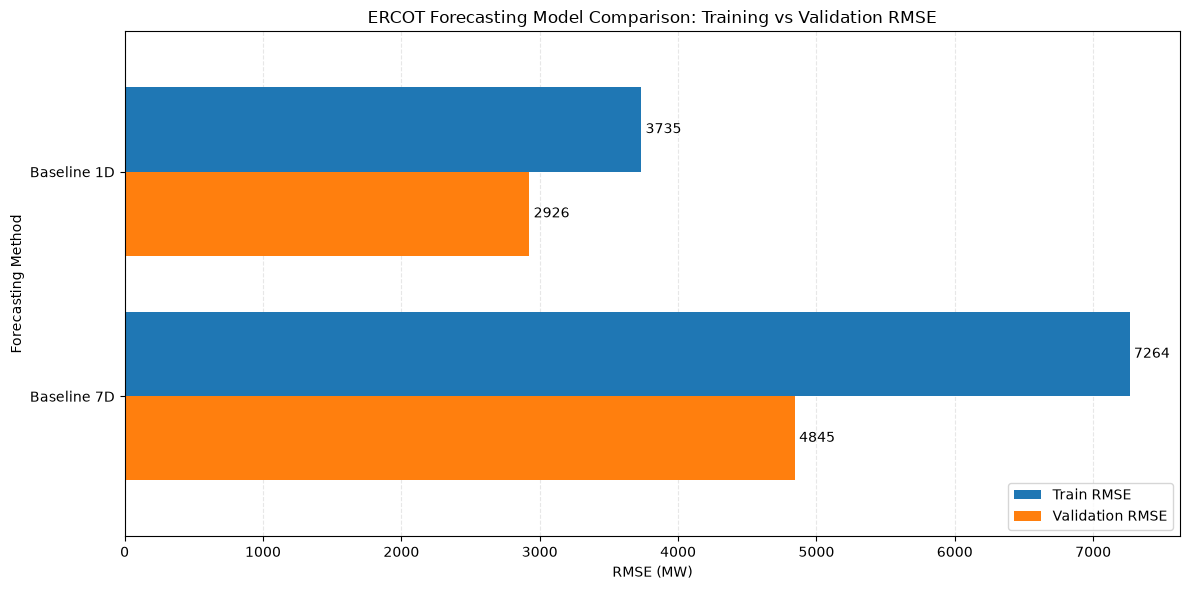

In [24]:
# Define a reusable function to compare training and validation RMSE.
def plot_model_comparison(metrics_df):
    ax = metrics_df[["Train RMSE", "Validation RMSE"]].plot(
        kind="barh",
        figsize=(12, 6),
        width=0.75
    )

    plt.title("ERCOT Forecasting Model Comparison: Training vs Validation RMSE")
    plt.xlabel("RMSE (MW)")
    plt.ylabel("Forecasting Method")

    ax.invert_yaxis() #Place the first model at the top of the chart.

    # Add subtle gridlines to make error magnitudes easier to compare.
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    plt.legend(loc="lower right")
    plt.tight_layout()
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)
    plt.show()

# Visualize the performance of both persistence baselines.
plot_model_comparison(all_metrics_df)

### Baseline Evaluation Results:
I evaluated two persistence forecasting methods on the validation dataset using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). The previous-day baseline achieved an MAE of 2,080.54 MW and RMSE of 2,925.94 MW, outperforming the previous-week baseline, which achieved an MAE of 3,871.44 MW and RMSE of 4,844.51 MW. This suggests that during the validation period, electricity demand from the immediately preceding day provided a more accurate forecast than demand from the same hour one week earlier. The previous-day baseline therefore serves as the stronger benchmark for evaluating subsequent machine learning models.

## 7. Model Training & Evaluation

### 7.1 Exploratory Feature-Target Relationship Analysis

#### 7.1.1 Correlation Analysis

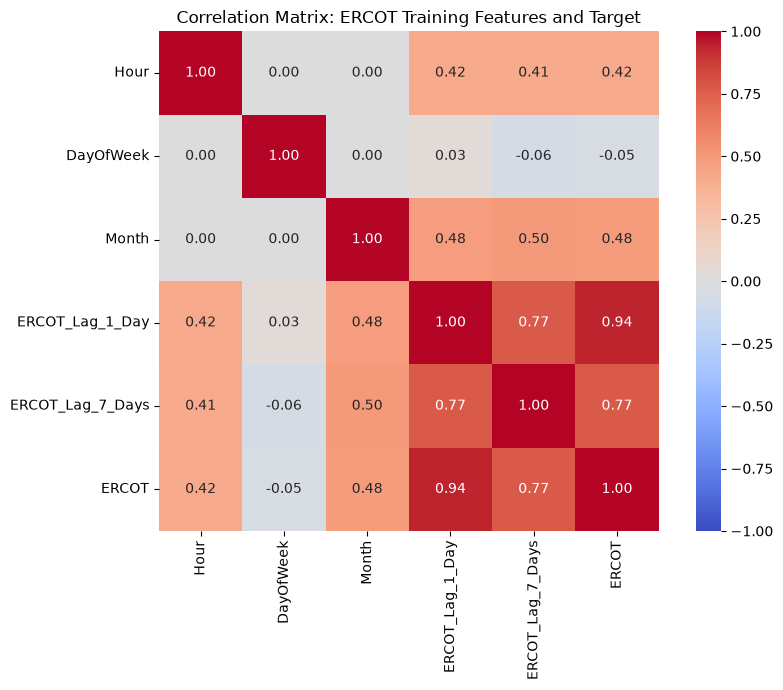

--- Feature Correlation with ERCOT Load ---
ERCOT_Lag_1_Day     0.938864
ERCOT_Lag_7_Days    0.769278
Month               0.484811
Hour                0.421127
DayOfWeek          -0.045263
Name: ERCOT, dtype: float64


In [25]:
import seaborn as sns

# Combine training features and target for exploratory analysis.
eda_train_df = X_train.copy()
eda_train_df["ERCOT"] = y_train

# Calculate Pearson correlation coefficients for all numerical variables.
correlation_matrix = eda_train_df.corr()

# Visualize pairwise linear relationships between features and the target.
plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
)

plt.title("Correlation Matrix: ERCOT Training Features and Target")
plt.tight_layout()
plt.show()

# Display correlations with ERCOT load in descending order.
print("--- Feature Correlation with ERCOT Load ---")
print(correlation_matrix["ERCOT"].drop("ERCOT").sort_values(ascending=False))

##### Correlation Analysis Comment:
Pearson correlation analysis revealed that ERCOT_Lag_1_Day had the strongest linear relationship with the target (r = 0.94), followed by ERCOT_Lag_7_Days (r = 0.77). This suggests that recent historical electricity demand provides substantial predictive information for next-day hourly load forecasting.

#### 7.1.2 Historical Load vs. Target

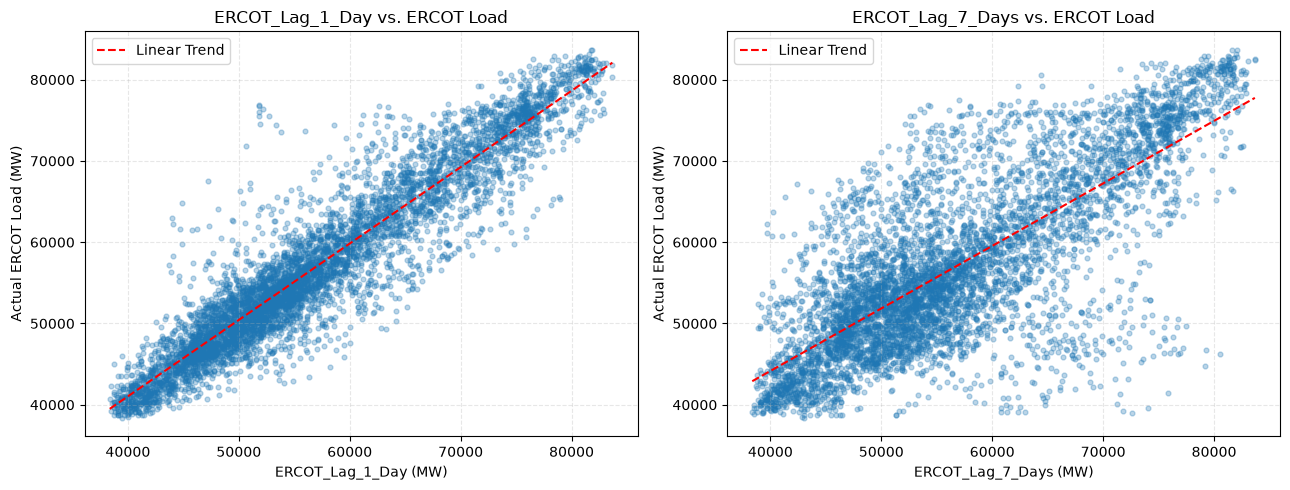

In [26]:
# Compare historical load features with the actual ERCOT target.

lag_features = ["ERCOT_Lag_1_Day", "ERCOT_Lag_7_Days"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feature in zip(axes, lag_features):
    ax.scatter(
        eda_train_df[feature],
        eda_train_df["ERCOT"],
        alpha=0.3,
        s=12,
    )

    # Add a fitted straight line as a visual reference.
    slope, intercept = np.polyfit(
        eda_train_df[feature],
        eda_train_df["ERCOT"],
        1,
    )

    x_line = np.linspace(
        eda_train_df[feature].min(),
        eda_train_df[feature].max(),
        100,
    )

    ax.plot(
        x_line,
        slope * x_line + intercept,
        color="red",
        linestyle="--",
        label="Linear Trend",
    )

    ax.set_title(f"{feature} vs. ERCOT Load")
    ax.set_xlabel(f"{feature} (MW)")
    ax.set_ylabel("Actual ERCOT Load (MW)")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

##### Historical Load vs Target Comment:
Scatter plots confirmed a strong positive, approximately linear relationship between previous-day load and actual ERCOT demand. The previous-week relationship was also positive but exhibited considerably greater dispersion, indicating a less consistent association. These observations supported using Linear Regression as an initial modeling approach while establishing the importance of historical-load persistence baselines.

#### 7.1.3 Calendar Features vs. ERCOT Load

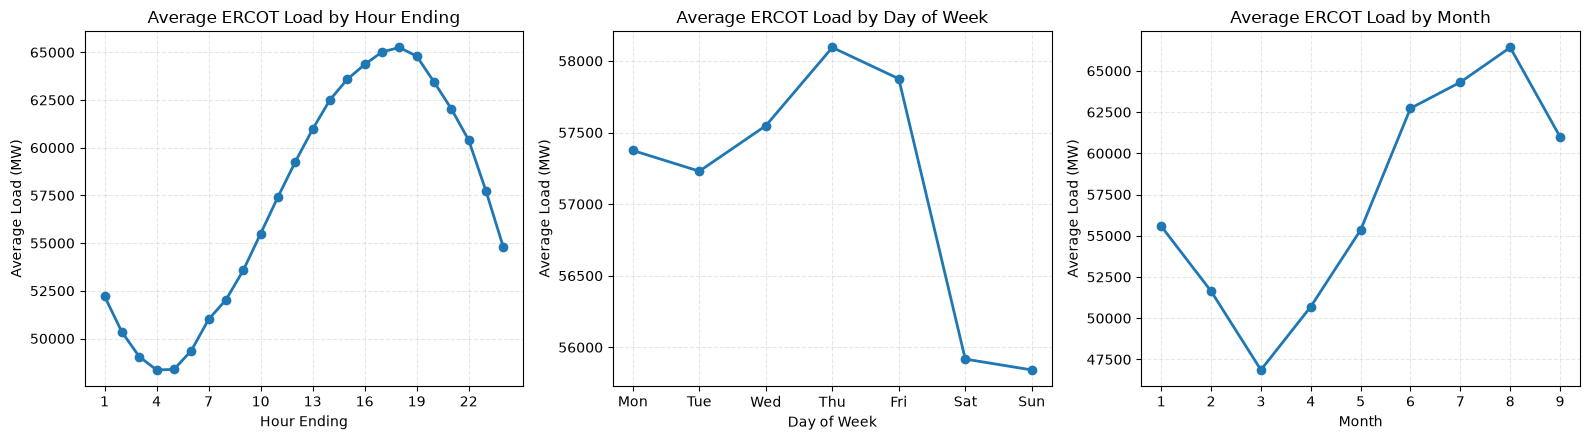

In [27]:
# Calculate average training-period ERCOT load by calendar feature.
# Grouping by calendar categories reveals recurring temporal patterns
# that may not be captured by Pearson correlation coefficients.

calendar_features = ["Hour", "DayOfWeek", "Month"]
calendar_labels = ["Hour Ending", "Day of Week", "Month"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, feature, label in zip(
    axes, calendar_features, calendar_labels
):
    avg_load = (
        eda_train_df.groupby(feature)["ERCOT"]
        .mean()
        .sort_index()
    )

    ax.plot(
        avg_load.index,
        avg_load.values,
        marker="o",
        linewidth=2,
    )

    ax.set_title(f"Average ERCOT Load by {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Average Load (MW)")
    ax.grid(True, linestyle="--", alpha=0.3)

    if feature == "DayOfWeek":
        ax.set_xticks(range(7))
        ax.set_xticklabels(
            ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
        )

    elif feature == "Month":
        ax.set_xticks(avg_load.index)

    elif feature == "Hour":
        ax.set_xticks(range(1, 25, 3))

plt.tight_layout()
plt.show()

##### Calendar Features vs ERCOT Load Comment:
Average training-period demand followed a pronounced intraday cycle, reaching its lowest level around hour endings 4–5 and peaking around hour ending 18. This pattern demonstrates that the relationship between hour and demand is not adequately summarized by a single linear correlation coefficient.

Weekly demand variation: Average electricity demand was relatively similar across weekdays, with Thursday recording the highest average load. Demand declined noticeably on weekends, particularly Saturday and Sunday. However, DayOfWeek had a weak linear correlation with the target (r = −0.05), demonstrating that low Pearson correlation does not necessarily imply an absence of meaningful calendar-related patterns.

Seasonal demand variation: Average monthly load declined from January through March before increasing toward the summer, reaching its highest observed training-period average in August. This suggests substantial seasonal variation, potentially associated with changing weather and electricity consumption patterns. However, weather variables were not included in this analysis, so their contribution cannot be directly established.

#### Feature-Target EDA Comment:
The exploratory analysis demonstrated that historical electricity demand was strongly associated with the forecasting target, while calendar variables exhibited additional temporal patterns. These findings justified evaluating both Linear Regression and nonlinear tree-based models to investigate whether more flexible relationships could improve forecasting accuracy.

Previous-day electricity demand emerged as the strongest individual predictor, while daily, weekly, and seasonal patterns provided additional context. The analysis established a foundation for subsequent model training, baseline comparisons, and evaluation of whether nonlinear models could improve upon historical-load persistence.

### 7.2 Linear Regressor Model

--- Model Performance Comparison (MW) ---
                   Train MAE  Train RMSE  Validation MAE  Validation RMSE
Baseline 1D          2616.93     3734.74         2080.54          2925.94
Baseline 7D          5114.61     7264.36         3871.44          4844.51
Linear Regression    2487.47     3486.20         2173.10          2964.28


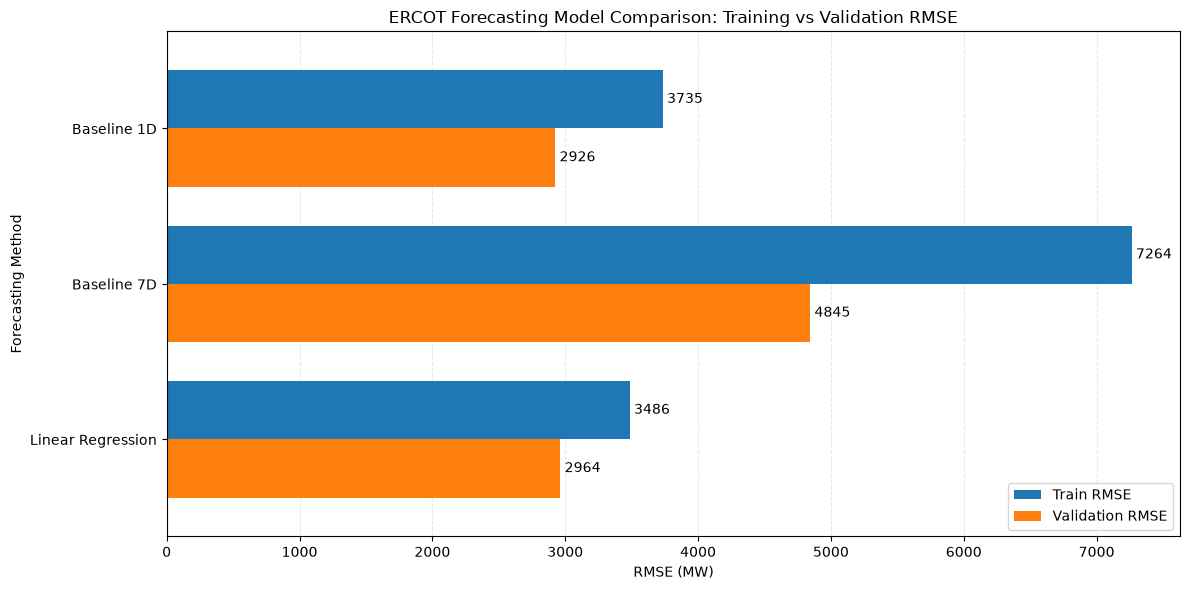

In [28]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Generate predictions for training and validation set
y_train_pred_lr = linear_model.predict(X_train)
y_val_pred_lr = linear_model.predict(X_val) 

# Calculate training and validation MAE and RMSE
linear_train_mae = mean_absolute_error(y_train, y_train_pred_lr)
linear_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_lr))
linear_mae = mean_absolute_error(y_val, y_val_pred_lr)
linear_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_lr))

# Compare Linear Model error metrics with the baseline models
all_metrics_df.loc["Linear Regression"] = [
    linear_train_mae,
    linear_train_rmse,
    linear_mae,
    linear_rmse
]

print("--- Model Performance Comparison (MW) ---")
print(all_metrics_df.round(2))

# Visualize the performance of the linear regression model alongside the persistence baselines
plot_model_comparison(all_metrics_df)

#### Linear Regression Evaluation:
I trained an initial multiple linear regression model using the five engineered calendar and historical load features (ReportingDate, Hour, DayOfWeek, Month, PreviousDaye, and PreviousWeek). The model was fitted using the training dataset and evaluated on the validation dataset. It achieved an MAE of 2,173.10 MW and RMSE of 2,964.28 MW.

Although Linear Regression substantially outperformed the previous-week persistence baseline, it did not outperform the previous-day baseline. This indicates that the initial linear model does not yet provide an improvement over the strongest simple forecasting method. Possible limitations include nonlinear electricity-demand patterns, unmodeled weather effects, and the numeric representation of calendar features.

The next stage will investigate nonlinear models and improved feature representations to determine whether forecasting accuracy can be improved.

### 7.3 Decision Tree Regressor Model

#### 7.3.1 Decision Tree Regressor Training & Evaluation

--- Model Performance Comparison (MW) ---
                   Train MAE  Train RMSE  Validation MAE  Validation RMSE
Baseline 1D          2616.93     3734.74         2080.54          2925.94
Baseline 7D          5114.61     7264.36         3871.44          4844.51
Linear Regression    2487.47     3486.20         2173.10          2964.28
Decision Tree           0.00        0.00         3331.13          4439.56


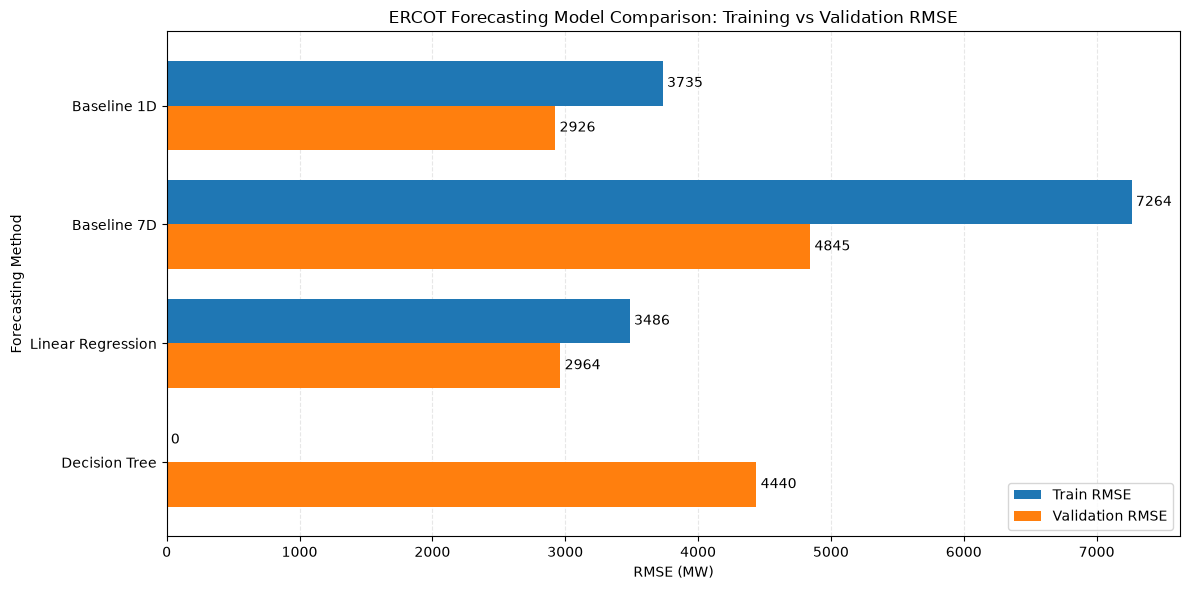

In [29]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

# Generate predictions for both training and validation sets
y_train_pred_dt = dt_model.predict(X_train)
y_val_pred_dt = dt_model.predict(X_val)

# Calculate training and validation MAE and RMSE
dt_train_mae = mean_absolute_error(y_train, y_train_pred_dt)
dt_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_dt))
dt_mae = mean_absolute_error(y_val, y_val_pred_dt)
dt_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_dt))

# Add the Decision Tree results to existing comparison table
all_metrics_df.loc["Decision Tree"] = [dt_train_mae, dt_train_rmse, dt_mae, dt_rmse] 

print("--- Model Performance Comparison (MW) ---")
print(all_metrics_df.round(2))

# Visualize the performance of the Decision Tree model alongside the existing models
plot_model_comparison(all_metrics_df)

##### Initial Decision Tree Regression Evaluation:
I trained a Decision Tree regressor using calendar features and historical ERCOT load observations to investigate whether nonlinear relationships could improve forecasting accuracy compared with Linear Regression and persistence baselines. The model achieved a training MAE and RMSE of 0.00 MW, indicating that it perfectly fitted the training observations. However, its validation MAE increased substantially to 3,331.13 MW, with an RMSE of 4,439.56 MW. 

This large gap between training and validation errors provides strong evidence of overfitting. Although the Decision Tree outperformed the previous-week persistence baseline (validation MAE: 3,871.44 MW), it performed significantly worse than Linear Regression (2,173.10 MW) and the previous-day persistence baseline (2,080.54 MW). 

These results suggest that the unrestricted Decision Tree learned highly specific patterns from the training data that did not generalize effectively to future electricity-demand observations. I will investigate the max_depth of the Decision Tree in the complexity analysis below.

#### 7.3.2 Decision Tree Hyperparameter Tuning

--- Decision Tree Depth Tuning Results ---
   max_depth  Train MAE  Train RMSE  Val MAE  Val RMSE
0          3    2876.44     3891.29  2476.18   3252.07
1          5    2502.35     3436.04  2298.18   3063.60
2         10    1543.89     2243.33  2597.85   3558.09
3         15     459.88      961.62  3232.21   4334.51
4         20      66.63      316.95  3154.19   4218.83


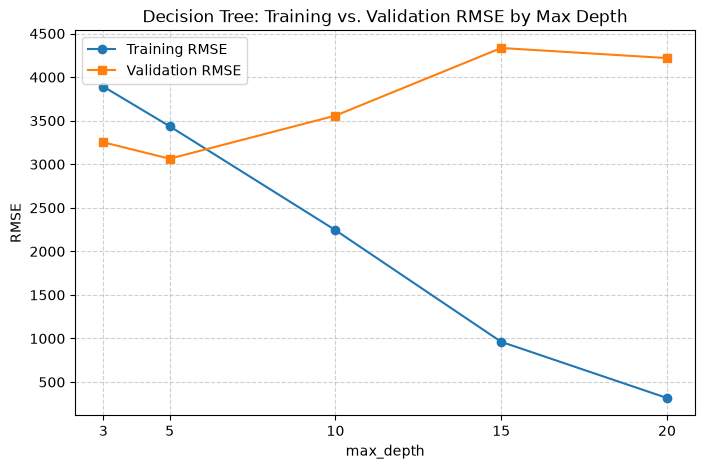

In [30]:
max_depth_values = [3, 5, 10, 15, 20] #Define candidate max_depth values

results = []

for depth in max_depth_values:
  dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
  dt.fit(X_train, y_train)

  train_pred = dt.predict(X_train) #Generate training predictions
  val_pred = dt.predict(X_val)

  train_mae = mean_absolute_error(y_train, train_pred) #Calculate training MAE
  train_rmse = np.sqrt(mean_squared_error(y_train, train_pred)) #Calculate training RMSE

  val_mae = mean_absolute_error(y_val, val_pred) #Calculate validation metrics
  val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

  # Append results as a dictionary
  results.append({
      "max_depth": depth,
      "Train MAE": train_mae,
      "Train RMSE": train_rmse,
      "Val MAE": val_mae,
      "Val RMSE": val_rmse,
  })

dt_depth_results = pd.DataFrame(results) #Convert results into a DataFrame
print("--- Decision Tree Depth Tuning Results ---")
print(dt_depth_results.round(2))

# Plot Training RMSE and Validation RMSE against max_depth on the same axes
plt.figure(figsize=(8, 5))
plt.plot(
    dt_depth_results["max_depth"],
    dt_depth_results["Train RMSE"],
    marker="o",
    label="Training RMSE",
)
plt.plot(
    dt_depth_results["max_depth"],
    dt_depth_results["Val RMSE"],
    marker="s",
    label="Validation RMSE",
)

plt.title("Decision Tree: Training vs. Validation RMSE by Max Depth")
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.xticks(max_depth_values)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

--- Updated Model Performance Comparison ---
                     Train MAE  Train RMSE  Validation MAE  Validation RMSE
Baseline 1D            2616.93     3734.74         2080.54          2925.94
Baseline 7D            5114.61     7264.36         3871.44          4844.51
Linear Regression      2487.47     3486.20         2173.10          2964.28
Decision Tree             0.00        0.00         3331.13          4439.56
Tuned Decision Tree    2502.35     3436.04         2298.18          3063.60


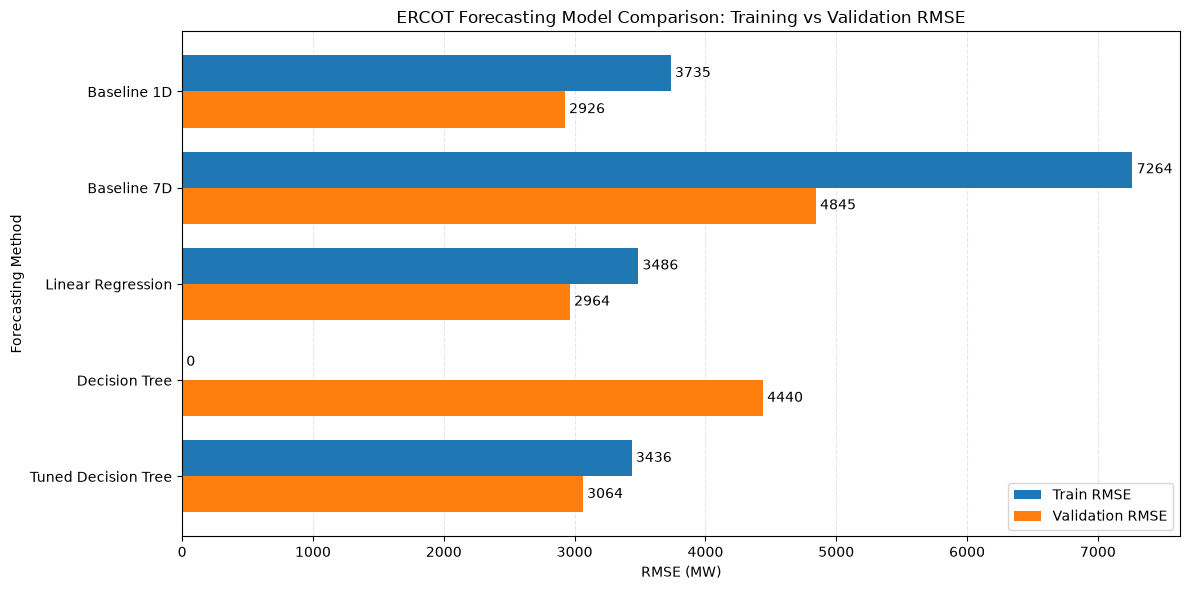

In [31]:
# Initialize the tuned Decision Tree with max_depth=5
dt_tuned_model = DecisionTreeRegressor(max_depth=5, random_state=42)

dt_tuned_model.fit(X_train, y_train) #Fit it on X_train and y_train

train_pred_tuned = dt_tuned_model.predict(X_train) # Generate training and validation predictions
val_pred_tuned = dt_tuned_model.predict(X_val)

train_mae_tuned = mean_absolute_error(y_train, train_pred_tuned) # Calculate both MAE and RMSE for each partition
train_rmse_tuned = np.sqrt(mean_squared_error(y_train, train_pred_tuned))

val_mae_tuned = mean_absolute_error(y_val, val_pred_tuned)
val_rmse_tuned = np.sqrt(mean_squared_error(y_val, val_pred_tuned))

# Add Tuned Decision Tree metric to comparison table
all_metrics_df.loc["Tuned Decision Tree"] = [
    train_mae_tuned, 
    train_rmse_tuned, 
    val_mae_tuned, 
    val_rmse_tuned
    ]

print("--- Updated Model Performance Comparison ---")
print(all_metrics_df.round(2))

plot_model_comparison(all_metrics_df)


#### Decision Tree Regressor Evaluation:
The unrestricted Decision Tree showed severe overfitting, with zero training error but a validation RMSE of 4,439.56 MW. To address this, I evaluated five maximum tree depths (3, 5, 10, 15, and 20) and selected max_depth=5 based on the lowest validation RMSE in the line chart. The tuned Decision Tree achieved a training MAE of 2,502.35 MW and RMSE of 3,436.04 MW, compared with a validation MAE of 2,298.18 MW and RMSE of 3,063.60 MW. Restricting tree depth reduced validation MAE and RMSE by approximately 31.0% compared with the unrestricted Decision Tree. The training and validation errors are now much closer, indicating that limiting model complexity improved generalization to the validation period. However, the tuned model still underperformed the previous-day persistence baseline, which achieved a validation RMSE of 2,925.94 MW. In conclusion, controlling tree complexity substantially improved validation performance, demonstrating the importance of hyperparameter tuning and the bias–variance tradeoff. The previous-day baseline remains the strongest forecasting method evaluated so far.

### 7.4 Random Forest Regressor Model

#### 7.4.1 Random Forest Training & Evaluation

--- Updated Model Performance Comparison ---
                     Train MAE  Train RMSE  Validation MAE  Validation RMSE
Baseline 1D            2616.93     3734.74         2080.54          2925.94
Baseline 7D            5114.61     7264.36         3871.44          4844.51
Linear Regression      2487.47     3486.20         2173.10          2964.28
Decision Tree             0.00        0.00         3331.13          4439.56
Tuned Decision Tree    2502.35     3436.04         2298.18          3063.60
Random Forest           737.89     1049.24         2263.94          2998.55


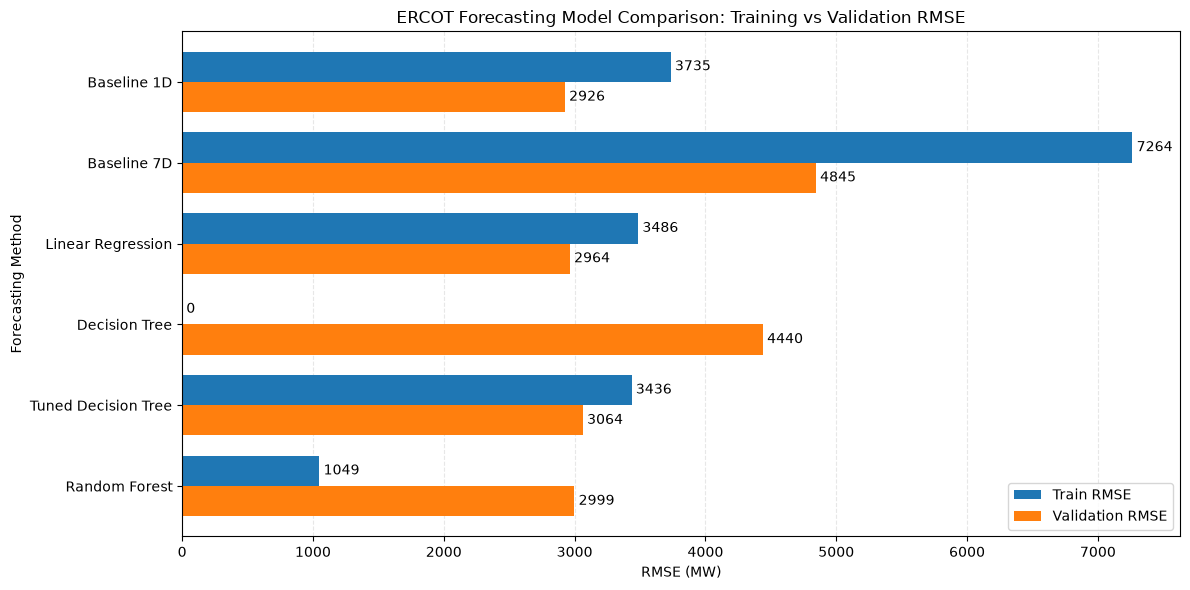

In [32]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train) #Fit the model using X_train and y_train

train_pred_rf = rf_model.predict(X_train) #Generate predictions for both X_train and X_val
val_pred_rf = rf_model.predict(X_val)

train_mae_rf = mean_absolute_error(y_train, train_pred_rf) 
train_rmse_rf = np.sqrt(mean_squared_error(y_train, train_pred_rf))

val_mae_rf = mean_absolute_error(y_val, val_pred_rf)
val_rmse_rf = np.sqrt(mean_squared_error(y_val, val_pred_rf))

# Add "Random Forest" to your existing all_metrics_df
all_metrics_df.loc["Random Forest"] = [train_mae_rf, train_rmse_rf, val_mae_rf, val_rmse_rf]

print("--- Updated Model Performance Comparison ---")
print(all_metrics_df.round(2))

plot_model_comparison(all_metrics_df)

##### Initial Random Forest Evaluation:
I trained a Random Forest regressor consisting of 100 Decision Trees to investigate whether ensemble learning could improve forecasting accuracy and reduce the overfitting observed in the unrestricted Decision Tree. The model achieved a training MAE of 737.89 MW and RMSE of 1,049.24 MW, compared with a validation MAE of 2,263.94 MW and RMSE of 2,998.55 MW.

Random Forest substantially outperformed the unrestricted Decision Tree and slightly improved upon the tuned Decision Tree. It also achieved a lower validation MAE than Linear Regression, although its validation RMSE remained slightly higher. The considerable difference between training and validation errors suggests that the Random Forest may still be overfitting, despite the variance reduction provided by ensemble learning.

The previous-day persistence baseline remains the strongest forecasting method, with a validation MAE of 2,080.54 MW and RMSE of 2,925.94 MW.

#### 7.4.2 Random Forest Hyperparameter Tuning

--- Random Forest Depth Tuning Results ---
   max_depth  Train MAE  Train RMSE  Val MAE  Val RMSE
0          5    2370.34     3280.25  2106.20   2849.66
1         10    1524.36     2050.92  2164.52   2883.86
2         15     893.68     1212.10  2249.97   2983.93
3         20     748.17     1057.93  2257.66   2995.40


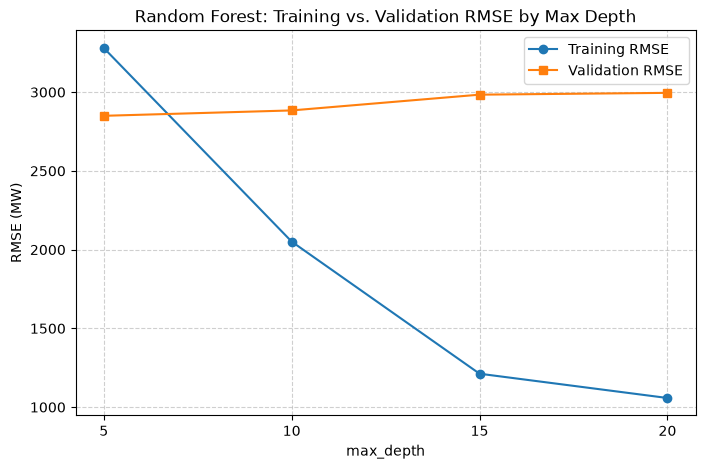


Best max_depth: 5 (Lowest Validation RMSE: 2849.66)


In [33]:
# Define candidate max_depth values
rf_depths = [5, 10, 15, 20]
rf_results = []

# Train a separate Random Forest for each depth and calculate metrics
for depth in rf_depths:
  rf = RandomForestRegressor(
      n_estimators=100, max_depth=depth, random_state=42
  )
  rf.fit(X_train, y_train)

  train_pred = rf.predict(X_train) #Generate predictions
  val_pred = rf.predict(X_val)

  # Calculate training and validation MAE and RMSE
  train_mae = mean_absolute_error(y_train, train_pred)
  train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
  val_mae = mean_absolute_error(y_val, val_pred)
  val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

  rf_results.append({
      "max_depth": depth,
      "Train MAE": train_mae,
      "Train RMSE": train_rmse,
      "Val MAE": val_mae,
      "Val RMSE": val_rmse,
  })

# Store the results in a DataFrame named rf_depth_results
rf_depth_results = pd.DataFrame(rf_results)
print("--- Random Forest Depth Tuning Results ---")
print(rf_depth_results.round(2))

# Create a line plot comparing training and validation RMSE against max_depth
plt.figure(figsize=(8, 5))
plt.plot(
    rf_depth_results["max_depth"],
    rf_depth_results["Train RMSE"],
    marker="o",
    label="Training RMSE",
)
plt.plot(
    rf_depth_results["max_depth"],
    rf_depth_results["Val RMSE"],
    marker="s",
    label="Validation RMSE",
)

plt.title("Random Forest: Training vs. Validation RMSE by Max Depth")
plt.xlabel("max_depth")
plt.ylabel("RMSE (MW)")
plt.xticks(rf_depths)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# Identify the depth with the lowest validation RMSE
best_row = rf_depth_results.loc[rf_depth_results["Val RMSE"].idxmin()]
best_depth = int(best_row["max_depth"])
best_val_rmse = best_row["Val RMSE"]

print(
    f"\nBest max_depth: {best_depth} (Lowest Validation RMSE:"
    f" {best_val_rmse:.2f})"
)

--- Updated Model Performance Comparison ---
                     Train MAE  Train RMSE  Validation MAE  Validation RMSE
Baseline 1D            2616.93     3734.74         2080.54          2925.94
Baseline 7D            5114.61     7264.36         3871.44          4844.51
Linear Regression      2487.47     3486.20         2173.10          2964.28
Decision Tree             0.00        0.00         3331.13          4439.56
Tuned Decision Tree    2502.35     3436.04         2298.18          3063.60
Random Forest           737.89     1049.24         2263.94          2998.55
Tuned Random Forest    2370.34     3280.25         2106.20          2849.66


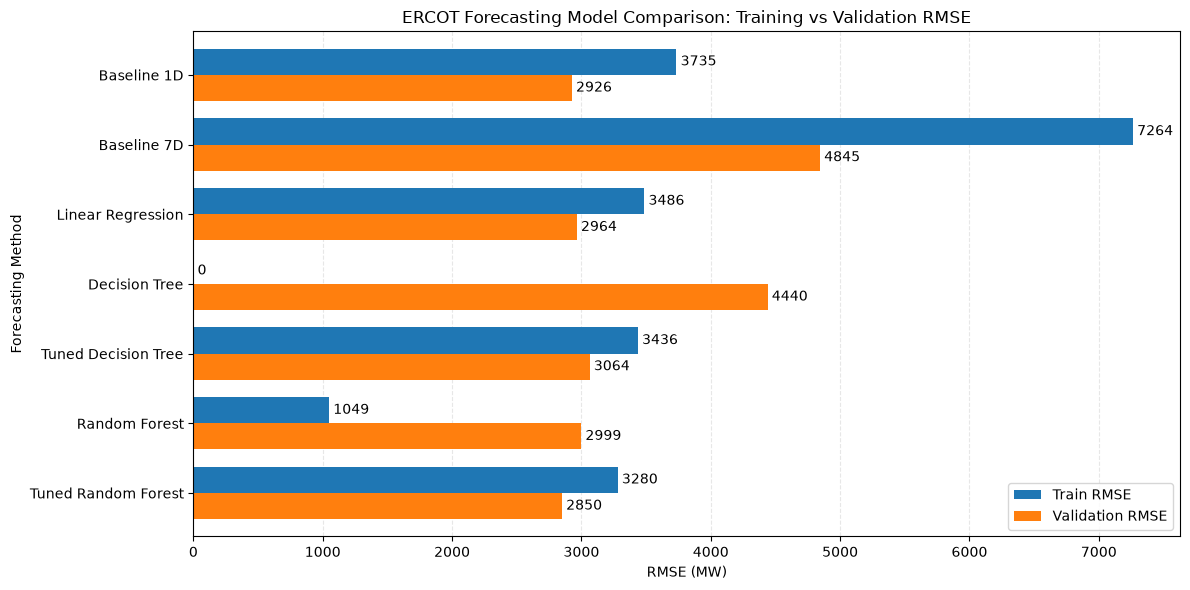

In [34]:
# Initialize the tuned Random Forest model
rf_tuned_model = RandomForestRegressor(
    n_estimators=100, max_depth=5, random_state=42
)

rf_tuned_model.fit(X_train, y_train)

train_pred_rf_tuned = rf_tuned_model.predict(X_train)
val_pred_rf_tuned = rf_tuned_model.predict(X_val)

train_mae_rf_tuned = mean_absolute_error(y_train, train_pred_rf_tuned)
train_rmse_rf_tuned = np.sqrt(mean_squared_error(y_train, train_pred_rf_tuned))

val_mae_rf_tuned = mean_absolute_error(y_val, val_pred_rf_tuned)
val_rmse_rf_tuned = np.sqrt(mean_squared_error(y_val, val_pred_rf_tuned))

# Add a row named "Tuned Random Forest" to all_metrics_df
all_metrics_df.loc["Tuned Random Forest"] = [
    train_mae_rf_tuned,
    train_rmse_rf_tuned,
    val_mae_rf_tuned,
    val_rmse_rf_tuned,
]

print("--- Updated Model Performance Comparison ---")
print(all_metrics_df.round(2))

plot_model_comparison(all_metrics_df)

#### Random Forest Regressor Evaluation:
To investigate the training–validation performance gap observed in the initial Random Forest, I evaluated maximum tree depths of 5, 10, 15, and 20 while keeping the number of estimators fixed at 100. The results demonstrate that increasing tree depth consistently reduced training error but did not improve validation performance. As depth increased from 5 to 20, training RMSE decreased from 3,280.25 MW to 1,057.93 MW, while validation RMSE increased from 2,849.66 MW to 2,995.40 MW.

The lowest validation RMSE was achieved at **max_depth=5**, indicating that a shallower Random Forest generalized better than the more complex configurations during the validation period. Compared with the initial unrestricted Random Forest (validation RMSE: 2,998.55 MW), the tuned model reduced validation RMSE by approximately 5.0%. The tuned Random Forest also achieved a lower validation RMSE than the previous-day persistence baseline (2,925.94 MW), representing an improvement of approximately 2.6%. However, its validation MAE of 2,106.20 MW remained slightly higher than the baseline's 2,080.54 MW.

Overall, restricting Random Forest depth improved validation performance and reduced the training–validation error gap. I selected max_depth=5 as the best configuration among those tested based on validation RMSE. The modest improvement over the persistence baseline requires confirmation using the held-out test dataset.


### 7.5 Model Selection Based on Validation Performance

In [35]:
# Sort all_metrics_df by "Validation RMSE" in ascending order without overwriting
rmse_col = ("Validation RMSE"
)
sorted_metrics_df = all_metrics_df.sort_values(by=rmse_col, ascending=True)

print("--- Sorted Model Performance Comparison (Validation Set) ---")
print(sorted_metrics_df.round(2))

# Identify the model with the lowest validation RMSE
best_model_name = sorted_metrics_df.index[0]
lowest_rmse = sorted_metrics_df.iloc[0][rmse_col]
print(
    f"\nBest Performing Model (Lowest RMSE): {best_model_name}"
    f" ({lowest_rmse:.2f})"
)

# Calculate the percentage improvement in RMSE of Tuned Random Forest over Baseline 1D
baseline_1d_rmse = all_metrics_df.loc["Baseline 1D", rmse_col]
tuned_rf_rmse = all_metrics_df.loc["Tuned Random Forest", rmse_col]

pct_improvement = (
    (baseline_1d_rmse - tuned_rf_rmse) / baseline_1d_rmse
) * 100
print(
    "RMSE Improvement (Tuned Random Forest vs. Baseline 1D):"
    f" {pct_improvement:.2f}%"
)

--- Sorted Model Performance Comparison (Validation Set) ---
                     Train MAE  Train RMSE  Validation MAE  Validation RMSE
Tuned Random Forest    2370.34     3280.25         2106.20          2849.66
Baseline 1D            2616.93     3734.74         2080.54          2925.94
Linear Regression      2487.47     3486.20         2173.10          2964.28
Random Forest           737.89     1049.24         2263.94          2998.55
Tuned Decision Tree    2502.35     3436.04         2298.18          3063.60
Decision Tree             0.00        0.00         3331.13          4439.56
Baseline 7D            5114.61     7264.36         3871.44          4844.51

Best Performing Model (Lowest RMSE): Tuned Random Forest (2849.66)
RMSE Improvement (Tuned Random Forest vs. Baseline 1D): 2.61%


### Final Model Training and Evaluation Result: 
After evaluating seven forecasting methods, including persistence baselines, Linear Regression, Decision Tree, and Random Forest models, I selected the **tuned Random Forest (`n_estimators=100`, `max_depth=5`)** as the primary candidate for final testing. The tuned Random Forest achieved the lowest validation RMSE of 2,849.66 MW, representing a 2.61% improvement over the previous-day persistence baseline (2,925.94 MW).

However, the previous-day baseline retained a slightly lower validation MAE (2,080.54 MW) than the tuned Random Forest (2,106.20 MW). Therefore, the tuned Random Forest demonstrated better performance on the selected RMSE metric, but not across all error metrics. The results also showed that restricting model complexity improved validation performance for both Decision Tree and Random Forest models, highlighting the importance of controlling overfitting.

The final selection is the Tuned Random Forest, with the previous-day persistence baseline retained as the main benchmark. The held-out test dataset has not been used during model development or hyperparameter selection and will now be used to assess final forecasting performance.

## 8. Model Performance Analysis & Interpretation

### 8.1 Final Test Evaluation

In [36]:
# Generate test predictions using the existing rf_tuned_model
test_pred_rf = rf_tuned_model.predict(X_test)

# Generate previous-day persistence predictions using ERCOT_Lag_1_Day from X_test
test_pred_baseline_1d = X_test["ERCOT_Lag_1_Day"]

# Calculate test MAE and RMSE for both methods against y_test
rf_test_mae = mean_absolute_error(y_test, test_pred_rf)
rf_test_rmse = np.sqrt(mean_squared_error(y_test, test_pred_rf))

base_test_mae = mean_absolute_error(y_test, test_pred_baseline_1d)
base_test_rmse = np.sqrt(mean_squared_error(y_test, test_pred_baseline_1d))

# Create test_metrics_df with model names as rows and "Test MAE" / "Test RMSE" as columns
test_metrics_df = pd.DataFrame(
    data={
        "Test MAE": [base_test_mae, rf_test_mae],
        "Test RMSE": [base_test_rmse, rf_test_rmse],
    },
    index=["Baseline 1D", "Tuned Random Forest"],
)

print("--- Final Test Set Performance Comparison ---")
print(test_metrics_df.round(2))

# Calculate percentage improvement (or deterioration) in test RMSE relative to the baseline
test_rmse_improvement = (
    (base_test_rmse - rf_test_rmse) / base_test_rmse
) * 100
status = "improvement" if test_rmse_improvement >= 0 else "deterioration"
print(
    f"\nTest RMSE {status} (Tuned Random Forest vs. Baseline 1D):"
    f" {abs(test_rmse_improvement):.2f}%"
)

--- Final Test Set Performance Comparison ---
                     Test MAE  Test RMSE
Baseline 1D           2351.07    3127.62
Tuned Random Forest   2325.87    3002.47

Test RMSE improvement (Tuned Random Forest vs. Baseline 1D): 4.00%


#### Final Test Evaluation Results: 
Following model selection based on validation RMSE, I evaluated the tuned Random Forest (`n_estimators=100`, `max_depth=5`) against the previous-day persistence baseline using the unseen chronological test dataset. The tuned Random Forest achieved a **test MAE of 2,325.87 MW** and **RMSE of 3,002.47 MW**, compared with the baseline's MAE of 2,351.07 MW and RMSE of 3,127.62 MW. This represents a **4.00% reduction in test RMSE** and approximately **1.07% reduction in test MAE** relative to the previous-day baseline.

The results indicate that the tuned Random Forest generalized successfully to the held-out test period and achieved modest improvements over the persistence benchmark on both evaluation metrics. Although these findings are encouraging, the improvements are limited to the evaluated period. Additional historical data, weather-related predictors, and time-series cross-validation could help assess robustness across different demand conditions.

### 8.2 Actual vs. Predicted Visualizations

#### 8.2.1 Hourly Forecast Comparison

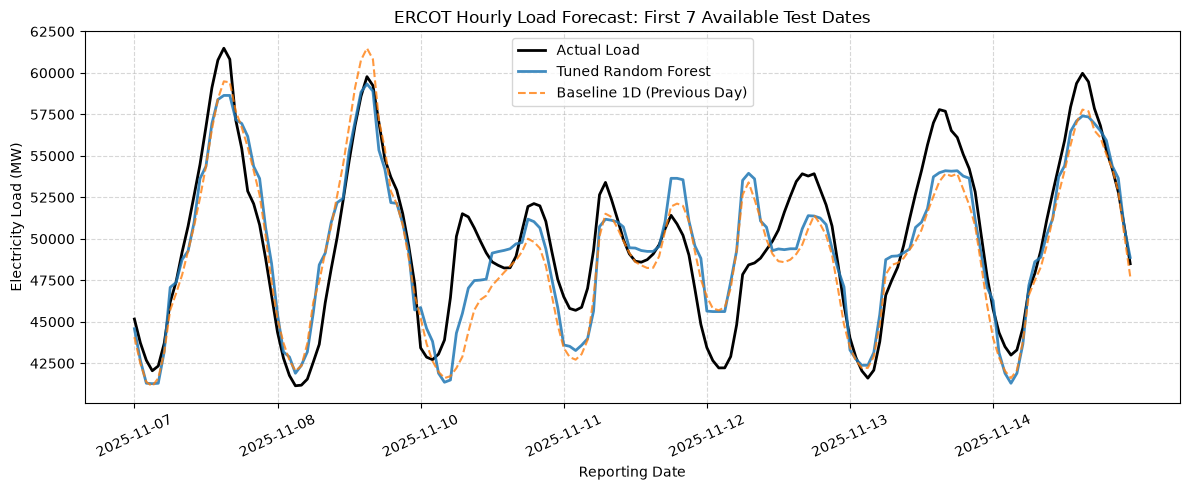

In [37]:
# Create DataFrame preserving row alignment with X_test / y_test
# Pull ReportingDate and Hour from model_df using X_test's index
test_results_df = pd.DataFrame(
    {
        "ReportingDate": model_df.loc[X_test.index, "ReportingDate"],
        "Hour": model_df.loc[X_test.index, "Hour"],
        "Actual Load": y_test,
        "Tuned Random Forest": test_pred_rf,
        "Baseline 1D": test_pred_baseline_1d,
    },
    index=X_test.index,
)

# Select the first seven available reporting dates in the test period
first_7_dates = sorted(test_results_df["ReportingDate"].unique())[:7]
sample_week_df = test_results_df[
    test_results_df["ReportingDate"].isin(first_7_dates)
].copy()

# Sort the selected observations by ReportingDate and Hour
sample_week_df = sample_week_df.sort_values(
    by=["ReportingDate", "Hour"]
).reset_index(drop=True)

# Plot all three load series as lines on the same chart
plt.figure(figsize=(12, 5))

plt.plot(
    sample_week_df.index,
    sample_week_df["Actual Load"],
    label="Actual Load",
    linewidth=2,
    color="black",
)
plt.plot(
    sample_week_df.index,
    sample_week_df["Tuned Random Forest"],
    label="Tuned Random Forest",
    linewidth=2,
    linestyle="-",
    alpha=0.85,
)
plt.plot(
    sample_week_df.index,
    sample_week_df["Baseline 1D"],
    label="Baseline 1D (Previous Day)",
    linewidth=1.5,
    linestyle="--",
    alpha=0.8,
)

plt.title("ERCOT Hourly Load Forecast: First 7 Available Test Dates")
plt.xlabel("Reporting Date")
plt.ylabel("Electricity Load (MW)")

day_ticks = range(0, len(sample_week_df), 24) #Add vertical grid lines at 24-hour intervals to mark day boundaries
day_labels = [
    str(d)[:10] for d in sample_week_df.loc[day_ticks, "ReportingDate"]
]
plt.xticks(ticks=day_ticks, labels=day_labels, rotation=25)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

##### Hourly Forecast Comparison Results:
I visualized actual ERCOT electricity demand alongside predictions from the tuned Random Forest and previous-day persistence baseline over the first seven available reporting dates in the test period. Both forecasting methods generally captured the recurring daily demand patterns, including periods of increasing demand, peak load, and overnight declines.

However, the tuned Random Forest underestimated several pronounced demand peaks, particularly around November 7 and November 13–14, and overestimated demand during some lower-load periods around November 11–12. These observations suggest that the model captures general demand patterns but struggles with certain rapid or unusually large changes.

The Random Forest and persistence baseline also produced similar predictions during several intervals, indicating that recent historical load is an informative forecasting signal. Neither method consistently outperformed the other at every hour in the visualized period. However, across the full unseen test dataset, the tuned Random Forest achieved a 4.00% lower RMSE than the previous-day baseline.

#### 8.2.2 Actual vs. Predicted Scatter Plot

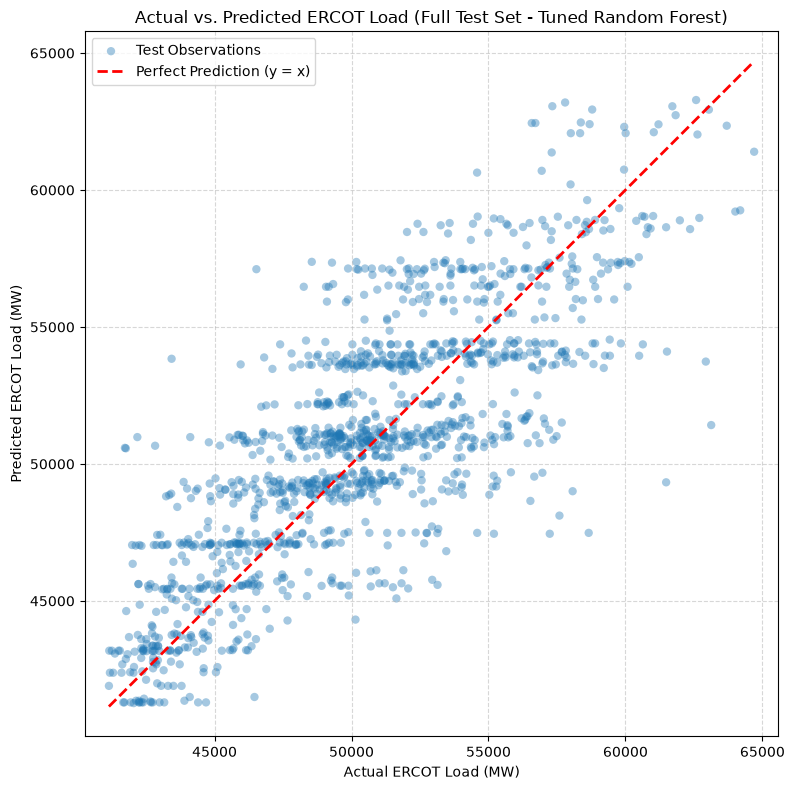

In [38]:
# Initialize the figure
plt.figure(figsize=(8, 8))

# Create scatter plot of actual load vs. tuned Random Forest predictions
# Use alpha=0.4 to reduce overlap across the full test dataset
plt.scatter(
    y_test,
    test_pred_rf,
    alpha=0.4,
    edgecolors="none",
    label="Test Observations",
)

# Add a diagonal reference line representing perfect predictions (y = x)
min_val = min(y_test.min(), test_pred_rf.min())
max_val = max(y_test.max(), test_pred_rf.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction (y = x)",
)

# Label both axes in MW and give the plot a descriptive title
plt.title(
    "Actual vs. Predicted ERCOT Load (Full Test Set - Tuned Random Forest)"
)
plt.xlabel("Actual ERCOT Load (MW)")
plt.ylabel("Predicted ERCOT Load (MW)")

# Keep aspect ratio equal so the 45-degree diagonal represents y = x accurately
plt.axis("equal")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

##### Actual vs. Predicted Load Scatter Plot Analysis:
I created an actual-versus-predicted scatter plot using all observations in the held-out test dataset to evaluate the tuned Random Forest's forecasting behavior across different electricity-demand levels.

The predictions generally follow a positive relationship with actual electricity demand, indicating that the model captures meaningful variation in hourly load. However, the scatter plot reveals several important limitations:
- **High-demand underprediction:** Several observations at higher actual load levels fall below the perfect-prediction line, indicating that the model underestimates some demand peaks.
- **Low-demand overprediction:** Some lower-demand observations fall above the reference line, suggesting that the model occasionally overestimates demand during lower-load periods.
- **Prediction clustering:** Horizontal concentrations of predicted values are visible, potentially reflecting the limited complexity of the tuned Random Forest (`max_depth=5`).

Together, these patterns suggest that the model captures overall demand trends but may struggle with extreme loads and certain demand fluctuations. Although the tuned Random Forest achieved lower overall test MAE and RMSE than the previous-day persistence baseline, its predictions are not equally accurate across all demand levels. Residual analysis will help investigate whether these apparent underprediction and overprediction patterns are systematic.

### 8.3 Residual Analysis and Feature Importance

#### 8.3.1 Residual Analysis

Mean Residual (Test Set): -374.92 MW


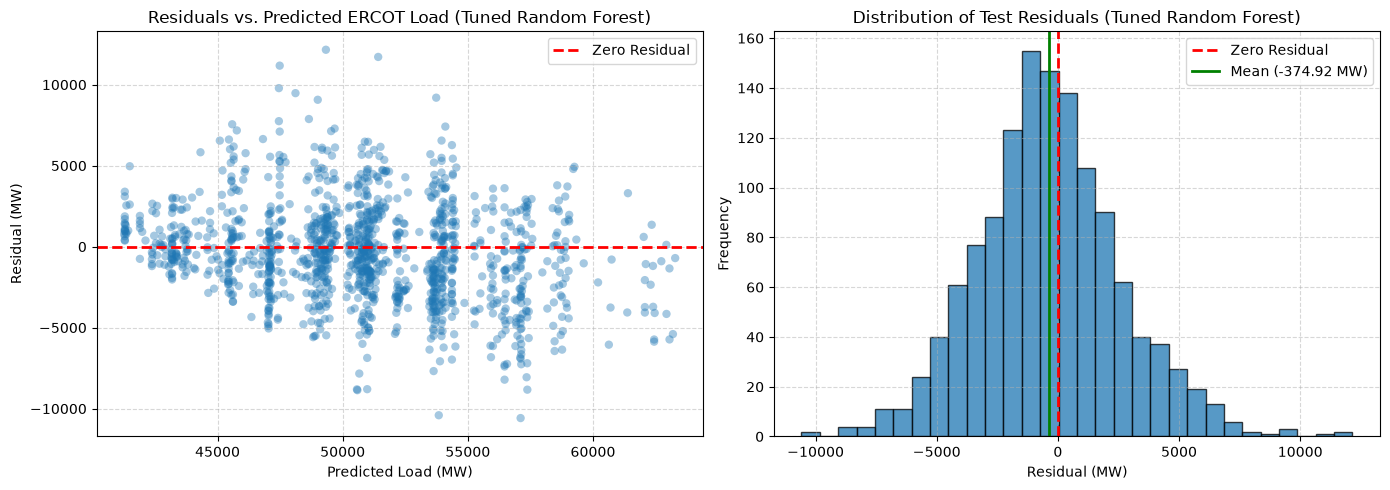

In [39]:
# Calculate residuals for the entire test dataset (Actual - Predicted)
residuals = y_test - test_pred_rf

# Calculate the mean residual to check for directional bias
mean_residual = np.mean(residuals)
print(f"Mean Residual (Test Set): {mean_residual:.2f} MW")

# Set up side-by-side subplots for the scatter plot and histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot with predicted load on x-axis and residuals on y-axis
axes[0].scatter(test_pred_rf, residuals, alpha=0.4, edgecolors="none")

# Add a horizontal reference line at zero residual
axes[0].axhline(
    y=0, color="red", linestyle="--", linewidth=2, label="Zero Residual"
)

axes[0].set_title(
    "Residuals vs. Predicted ERCOT Load (Tuned Random Forest)"
)
axes[0].set_xlabel("Predicted Load (MW)")
axes[0].set_ylabel("Residual (MW)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Create a histogram of the residuals to examine their distribution
axes[1].hist(residuals, bins=30, edgecolor="black", alpha=0.75)
axes[1].axvline(
    x=0, color="red", linestyle="--", linewidth=2, label="Zero Residual"
)
axes[1].axvline(
    x=mean_residual,
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Mean ({mean_residual:.2f} MW)",
)

axes[1].set_title("Distribution of Test Residuals (Tuned Random Forest)")
axes[1].set_xlabel("Residual (MW)")
axes[1].set_ylabel("Frequency")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

##### Residual Analysis Results:
To investigate forecasting errors beyond aggregate MAE and RMSE, I calculated residuals as the difference between actual and predicted ERCOT electricity demand for the test dataset. The tuned Random Forest produced a mean residual of −374.92 MW, indicating a modest overall tendency to overpredict electricity demand.

The residual histogram is approximately bell-shaped and centered near zero, although several large positive and negative errors are present. These extreme residuals help explain why RMSE is higher than MAE. The residual-versus-predicted plot reveals some structure rather than a completely random distribution around zero. Residuals tend to become more negative at higher predicted load levels, suggesting that prediction errors may vary with forecasted demand.

Vertical clusters of residuals are also visible, consistent with the prediction clustering observed in the actual-versus-predicted scatter plot. This may partly reflect the limited complexity of the tuned Random Forest. Although the model improves upon the previous-day persistence baseline in overall test MAE and RMSE, residual analysis reveals a modest overprediction bias and nonuniform error patterns. Future improvements could investigate additional predictors, particularly weather-related variables, to better capture demand fluctuations and extreme conditions.

#### 8.3.2 Random Forest Feature Importance

--- Feature Importance (Tuned Random Forest) ---
            Feature  Importance
0   ERCOT_Lag_1_Day      0.9750
1  ERCOT_Lag_7_Days      0.0170
2         DayOfWeek      0.0060
3             Month      0.0013
4              Hour      0.0006


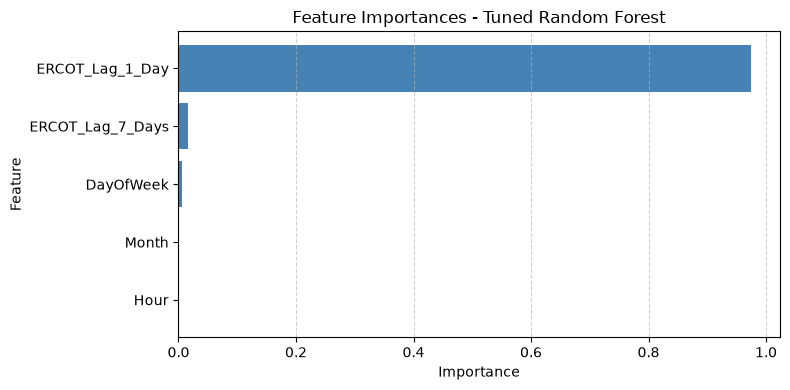

In [40]:
# Access the fitted rf_tuned_model object's feature_importance_ attribute
importance = rf_tuned_model.feature_importances_

# Match importance values to feature names in X_train.columns and create DataFrame
feature_importance_df = pd.DataFrame(
    {"Feature": X_train.columns, "Importance": importance}
)

# Sort the DataFrame by importance in descending order
feature_importance_df = feature_importance_df.sort_values(
    by="Importance", ascending=False
).reset_index(drop=True)

print("--- Feature Importance (Tuned Random Forest) ---")
print(feature_importance_df.round(4))

plt.figure(figsize=(8, 4))
plot_df = feature_importance_df.iloc[::-1] # Reverse the order for barh so the most important feature appears at the top

plt.barh(plot_df["Feature"], plot_df["Importance"], color="steelblue")
plt.title("Feature Importances - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

##### Random Forest Feature Importance Results:
I examined the tuned Random Forest's impurity-based feature importances to understand which predictors contributed most to its forecasting decisions.

The results show that previous-day ERCOT load (`ERCOT_Lag_1_Day`) dominated feature importance at approximately 97.5%, followed by previous-week load (`ERCOT_Lag_7_Days`) at 1.7%. Calendar features contributed comparatively little to the model's measured importance.

This suggests that recent historical electricity demand was the primary predictive signal used by the fitted Random Forest. The finding is consistent with the similarity between the Random Forest and previous-day persistence forecasts observed in the hourly comparison chart.

However, feature importance measures the contribution of predictors to reducing impurity within the trained forest. It does not establish causal relationships or represent the percentage of electricity demand explained by each feature. Correlated predictors may also share predictive information.

### Model Performance Analysis Comment:
Historical load, particularly the previous day's demand at the same hour, was the dominant predictor in this model. Future improvements could investigate weather forecasts, additional lag features, and richer calendar representations to determine whether they provide meaningful predictive information beyond previous-day demand.

## 9. Conclusion

### 9.1 Assumptions:
1. **Forecast issuance and data availability:** This project assumes that the preceding reporting day's complete ERCOT load profile is available when the next day's forecast is issued. In an operational setting, actual ERCOT data publication latency and the forecast issuance cutoff would need to be verified to ensure that all historical load features are available at prediction time.

2. **Historical demand as a predictor:** The forecasting approach assumes that previous-day and previous-week electricity demand contain useful information about the following day's hourly demand patterns.

3. **Forecasting scope:** The objective is to predict all 24 hourly ERCOT load observations for the next reporting date using calendar features and historical demand, without relying on actual load observations from the forecasted date.

### 9.2 Findings:
1. **Data Preparation and Cleaning (Sections 2-3):** The 2025 ERCOT native-load dataset contained 8,760 hourly observations and 10 columns. The dataset was processed to extract reporting dates and hourly observations. Incomplete daylight-saving-time reporting dates were excluded from the forecasting targets to maintain consistent 24-hour daily profiles.

2. **Feature Engineering (Section 4):** Calendar features (Hour, DayOfWeek, and Month) and historical load features (ERCOT_Lag_1_Day and ERCOT_Lag_7_Days) were constructed. After removing observations with unavailable lag values and incomplete reporting dates, the final modeling dataset contained 8,448 hourly observations across 352 complete reporting dates.

3. **Chronological Data Partitioning (Sections 5):** The dataset was divided chronologically into training (70%), validation (approximately 15%), and test (approximately 15%) partitions, preserving complete reporting dates. This approach avoided random mixing of earlier and later observations and reserved the test period for final evaluation.

4. **Persistence Baselines (Section 6):** Two baseline forecasting methods were evaluated using previous-day and previous-week electricity demand. The previous-day persistence baseline performed substantially better, achieving a validation MAE of 2,080.54 MW and RMSE of 2,925.94 MW, establishing a strong benchmark for subsequent models.

5. **Exploratory Feature–Target Relationship Analysis (Section 7.1):** Pearson correlation analysis revealed a strong positive relationship between previous-day ERCOT load (ERCOT_Lag_1_Day) and the forecasting target (r = 0.94), followed by previous-week load (ERCOT_Lag_7_Days, r = 0.77). Scatter plots supported these relationships, while calendar-based visualizations revealed distinct hourly, weekly, and seasonal demand patterns. These findings established historical electricity demand as an important predictive signal and supported the evaluation of both linear and nonlinear regression models.

6. **Initial Model Training (Sections 7.2–7.4):** Linear Regression, Decision Tree, and Random Forest regressors were trained and compared using MAE and RMSE. Linear Regression performed relatively consistently across training and validation periods but did not outperform the previous-day baseline. The unrestricted Decision Tree exhibited severe overfitting, achieving 0 training error but a validation RMSE of 4,439.56 MW.

7. **Hyperparameter Tuning (Sections 7.3–7.4):** Restricting tree depth improved validation performance for both Decision Tree and Random Forest models. The tuned Random Forest (n_estimators=100, max_depth=5) achieved the lowest validation RMSE of 2,849.66 MW, representing a 2.61% improvement over the previous-day persistence baseline. However, its validation MAE remained slightly higher than the baseline.

8. **Final Model Selection and Test Evaluation (Sections 7.5 and 8.1):** The tuned Random Forest was selected using validation RMSE and evaluated on the held-out test dataset. It achieved a test MAE of 2,325.87 MW and RMSE of 3,002.47 MW, outperforming the previous-day baseline (MAE: 2,351.07 MW; RMSE: 3,127.62 MW). This represented a 1.07% reduction in MAE and 4.00% reduction in RMSE over the test period.

9. **Forecast Visualization and Residual Analysis (Sections 8.2–8.3.1):** The tuned Random Forest generally captured recurring daily demand patterns but exhibited errors around some peaks, troughs, and rapid demand changes. Actual-versus-predicted and residual plots revealed possible systematic error patterns, including underprediction at some high actual load levels and overprediction at some lower levels. The mean test residual of −374.92 MW indicated a modest overall overprediction bias.

10. **Feature Importance (Section 8.3.2):** Previous-day load (ERCOT_Lag_1_Day) accounted for approximately 97.5% of the fitted Random Forest's impurity-based feature importance. This indicates that the model relied heavily on recent historical demand, helping explain the similarity between its predictions and the previous-day persistence baseline. This percentage describes the model's split-impurity reduction, not the proportion of electricity demand explained by the feature.

### 9.3 Limitations:
1. **Limited predictor variables:** The models use only historical electricity demand and basic calendar features. Weather forecasts, holidays, and other external factors that may influence electricity consumption were not incorporated.

2. **Limited historical coverage:** The analysis uses only one year of ERCOT data (2025), limiting the ability to assess model performance across multiple years and unusual seasonal conditions.

3. **Daylight-saving-time exclusions:** Reporting dates with incomplete or ambiguous hourly observations were excluded from the modeling process. Consequently, the model has not been evaluated on all calendar dates, particularly those affected by daylight-saving transitions.

4. **Forecast data availability:** The study assumes that previous-day load observations are available before forecast issuance. Actual operational data publication schedules were not verified.

5. **Limited hyperparameter exploration:** Decision Tree and Random Forest tuning focused on max_depth using a single chronological validation period. Other hyperparameters and expanding-window time-series cross-validation were not investigated.

6. **Forecasting errors at demand extremes:** The model exhibited errors around some high-demand peaks and lower-demand periods. These limitations may be important in operational settings where large forecasting errors could affect planning decisions.

7. **Limited generalizability:** Although the tuned Random Forest outperformed the persistence baseline on the held-out test period, the improvement was modest and has not been verified across multiple independent years or operational forecasting environments.

### 9.4 Next Steps:
1. **Expand the dataset:** Incorporate additional years of ERCOT load data to capture a broader range of seasonal patterns and demand conditions.

2. **Integrate external predictors:** Add weather forecasts, particularly temperature, along with holiday indicators and other relevant variables. Ensure that all predictors would be available at the forecast issuance time.

3. **Improve feature engineering:** Investigate additional historical load lags, rolling statistics, and richer calendar representations to capture demand patterns not fully explained by previous-day load.

4. **Implement time-series cross-validation:** Use expanding-window validation with date-aligned folds to assess model stability and conduct more robust hyperparameter selection.

5. **Explore additional forecasting algorithms:** Evaluate methods such as gradient boosting and dedicated time-series forecasting approaches to determine whether they improve accuracy beyond Random Forest and persistence baselines.

6. **Investigate extreme-demand forecasting:** Examine model performance during high-load periods, rapid demand changes, and different seasons to identify opportunities for targeted improvements.

7. **Assess operational applicability:** Verify ERCOT data availability, establish a realistic forecast issuance schedule, and evaluate whether the forecasting pipeline can be adapted for practical day-ahead electricity-demand prediction.